In [64]:
try:
    import cabana
except ImportError:
    %pip install -q git+https://github.com/miniscope/CaBaNA.git
    import cabana

# CaBaNA: one framework for place cells, social behavior and syllables

**Question this notebook answers:** can place-cell analysis and social-behavior analysis really share one framework?

The claim is that, once behavior is written in a common form, the *middle* of the analysis is identical:

- the **same metric code** (information content, AUROC, stability, population-vector overlap) runs on a 2D spatial grid, on scored social bouts, and on behavioral syllables;
- the **same circular-shift engine** gives a null distribution for each of them.

To check that this works we use a simulated session where we *know* which cells are tuned to what, then see whether the pipeline finds them (and does not find the others).

**Second half of the notebook:** the same session and the same pipeline machinery also give peri-event time histograms, mean activity per state, correlation with speed, population PCA and decoding on re-binned data, a GLM, overlap between cell classes, response clusters, and a cohort check. Changing the null distribution is a one-line change.

## The three-array idea

Every analysis here reduces to three arrays on the neural clock:

| object | shape | meaning |
| --- | --- | --- |
| **activity** | `(n_cells, n_time)` | deconvolved calcium, dF/F, or binned spikes |
| **states** | `(n_time, n_states)` bool | which behavioral state(s) the animal is in at each frame |
| **mask** | `(n_time,)` bool | which frames count at all (speed threshold, "was this stretch scored?") |

- A **spatial bin** is a state ("the animal is in bin 17"). A 2D arena is just a state space with a grid topology that remembers which bins are neighbors (needed for smoothing and for drawing maps).
- A **social bout** is a state ("sniffing"). States can overlap, because an animal can sniff while chasing.
- A **syllable** is a state ("still", "run", ...). Syllables are exclusive: exactly one per frame.

What a metric is computed against (a state space, or a continuous signal such as speed) is called its **target**. Metrics only ever see these three arrays. They never ask "is this space, or social behavior?".

## 1. Simulate a session with planted ground truth

`simulate_session` builds a 2D arena trajectory (with stationary pauses), scored social bouts (sniff, groom, chase, huddle), and kinematic syllables, and plants four disjoint cell populations: **place cells**, **social cells** (half excited, half inhibited), **syllable cells**, and **untuned cells** that fire at baseline only. The answer key lives in `session.meta["ground_truth"]`.

In [65]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cabana import AnalysisSpec, Pipeline, ShuffleConfig, simulate_session

N_SHUFFLES = 500
N_CELLS = 400        # simulated cells
DURATION_S = 1800.0  # session length, seconds (30 min)
session = simulate_session(seed=0, n_cells=N_CELLS, duration_s=DURATION_S)
gt = session.meta["ground_truth"]
sim = session.meta["simulation"]
social = gt["social_cells"]
n_exc = sum(d["sign"] == "excited" for d in social)
print(
    f"{sim['n_cells']} cells, {sim['duration_s']:.0f} s at {sim['fs']:g} Hz. Planted: "
    f"{len(gt['place_cells'])} place cells, {len(social)} social cells "
    f"({n_exc} excited / {len(social) - n_exc} inhibited), "
    f"{len(gt['syllable_cells'])} syllable cells, {len(gt['untuned_cells'])} untuned cells."
)
print("example social cells:", social[:4])

400 cells, 1800 s at 20 Hz. Planted: 120 place cells, 80 social cells (40 excited / 40 inhibited), 40 syllable cells, 100 untuned cells.
example social cells: [{'cell': 4, 'behavior': 'sniff', 'sign': 'excited'}, {'cell': 5, 'behavior': 'sniff', 'sign': 'inhibited'}, {'cell': 13, 'behavior': 'groom', 'sign': 'excited'}, {'cell': 14, 'behavior': 'groom', 'sign': 'inhibited'}]


## 2. One pipeline

A `Pipeline` is three ordered lists: **transforms** (raw behavior to states), **preprocess** steps (masks, smoothing), and **analyses** (metric x states x optional shuffle). Each step is a small registered plugin whose parameters are its fields, so the whole pipeline can be written to YAML.

### What each transform does

| transform | what it does |
| --- | --- |
| `resample_signal(source="position")` | Behavior is tracked on its own clock (here 30 Hz, offset from the neural clock). This interpolates the x/y signals onto the neural frames. |
| `speed()` | Computes per-frame speed from x/y over a short window. |
| `bin_grid(signals=["x","y"], bin_size=20)` | Cuts the arena into 20 mm squares and makes each square a state. Output: a *spatial* state space with grid topology (support: frames where the animal was tracked and inside the arena). |
| `bouts_to_states(source="social")` | Turns scored bouts (start, stop, label) into a boolean state matrix, one column per behavior, overlaps allowed. Its **support** (the scored span) is also written as the mask `social_scored`. |
| `labels_to_states(source="syllables")` | Turns a per-frame label series into an exclusive categorical state space. Its support is the span covered by labels. |

### Why unscored is not rest: support and masks

Social bouts are only scored inside a window (here 30 s after the start to 30 s before the end). Frames outside it, or frames with no bout inside it, are **not** "rest" automatically: the experimenter may simply not have scored them. So `bouts_to_states` does not invent a rest state; it records the scored span as the state space's **support**, the frames where the space is defined. Every analysis runs on its target's support automatically, so you never list `social_scored` yourself. (Bin frames with missing tracking and frames outside the labelled span are likewise outside the support of their spaces.)

On top of the support, `AnalysisSpec(masks=[...])` adds criteria that belong to one analysis only:

- **Place cells:** also keep only frames where the animal is moving (`speed_threshold`, 20 mm/s), the standard way to remove immobility-related activity from spatial maps.
- **Social behavior:** do *not* apply the speed mask. Huddling is stationary, so a speed filter would throw away exactly the behavior of interest.
- **Syllables:** no extra mask. "still" is one of the syllables we want to keep.

`masks=None` and `masks=[]` both mean "support only". Each analysis also gets a **name**, `metric[target]` by default (for example `auroc[social]`), which is how we pick results out below: `results["auroc[social]"]`.


In [66]:
shuf = ShuffleConfig(n_shuffles=N_SHUFFLES, min_shift_s=20.0, seed=0)

pipe = Pipeline(
    transforms=[
        {"name": "resample_signal", "source": "position"},
        {"name": "speed"},
        # IMU quaternion -> head_yaw / head_pitch / head_roll (degrees)
        {"name": "resample_signal", "source": "head_orientation"},
        {"name": "head_orientation"},
        # fixed arena extent: the same grid in every session (needed later for cross-session maps)
        {"name": "bin_grid", "signals": ["x", "y"], "bin_size": 20.0, "output": "position",
         "extent": [(0.0, 400.0), (0.0, 400.0)]},
        {"name": "bouts_to_states", "source": "social", "output": "social"},
        {"name": "labels_to_states", "source": "syllables", "output": "syllables"},
    ],
    preprocess=[{"name": "speed_threshold", "min_speed": 20.0}],
    analyses=[
        # spatial: same functions as syllables below, applied to grid bins
        AnalysisSpec(metric={"name": "information_content", "smooth_sigma_bins": 1.0},
                     states="position", shuffle=shuf, masks=["speed"]),
        AnalysisSpec(metric={"name": "split_half_stability", "smooth_sigma_bins": 1.0},
                     states="position", shuffle=shuf, masks=["speed"]),
        AnalysisSpec(metric={"name": "pv_stability"}, states="position",
                     shuffle=shuf, masks=["speed"]),
        # social: NOT speed-filtered (huddling is stationary); the scored span is the support
        AnalysisSpec(metric={"name": "auroc"}, states="social", shuffle=shuf),
        # pearson: cosine on max-scaled rates is ~0.95 for any pair (most cells fire alike everywhere)
        AnalysisSpec(metric={"name": "population_vector_overlap", "similarity": "pearson"}, states="social",
                     shuffle=shuf),  # p-value per state pair
        # syllables: no extra mask, 'still' is a syllable we want to keep
        AnalysisSpec(metric={"name": "information_content"}, states="syllables", shuffle=shuf),
        AnalysisSpec(metric={"name": "auroc"}, states="syllables", shuffle=shuf),
    ],
)

t0 = time.perf_counter()
session, results = pipe.run(session, progress=True)
print(f"\nPipeline runtime: {time.perf_counter() - t0:.1f} s")

[transform] resample_signal
[transform] speed
[transform] resample_signal
[transform] head_orientation
[transform] bin_grid
[transform] bouts_to_states
[transform] labels_to_states
[preprocess] speed_threshold
[analyze] information_content[position]
[analyze] split_half_stability[position]
[analyze] pv_stability[position]
[analyze] auroc[social]
[analyze] population_vector_overlap[social]
[analyze] information_content[syllables]
[analyze] auroc[syllables]

Pipeline runtime: 90.4 s


### The same metric on space and on syllables

Look at the analysis list above: `information_content` appears on `position` (grid bins) *and* on `syllables`, and `auroc` appears on `social` *and* on `syllables`. It is literally the same class and the same `compute` function. Skaggs information is just "how much does knowing the state tell you about the cell's firing?", whether the state is a 20 mm square, a syllable, or a social behavior. The only thing that differs is the state space handed in: spatial grids additionally carry a topology, which allows optional smoothing (`smooth_sigma_bins`) and map plotting.

### How the circular-shift null works

To ask whether a cell's relationship to behavior is more than chance, we need a null that keeps everything *except* the alignment: the cell's firing statistics (bursting, slow drifts, rate) and the behavior's statistics (bout durations, autocorrelation) stay intact. The engine therefore:

1. rolls each cell's whole activity trace by a random offset (at least `min_shift_s` = 20 s, so no shuffle is nearly aligned with the data), wrapping around the end;
2. recomputes the metric against the **unshifted** states and mask;
3. repeats N times; the p-value is `(count of shuffles at least as extreme + 1) / (N + 1)`.

**Why shifting happens in wall-clock time before masking.** The shift is applied to the full recording, and only then are masked frames dropped. If instead we first dropped masked frames and shuffled the remainder, we would be shuffling a stitched-together trace in which distant moments have been made adjacent, and the null would no longer preserve the real temporal structure of the activity. Shifting first keeps the cell's own time course intact, and the mask then removes exactly the same frames it removes for the real data.

The **tail** says which side of the null counts as extreme (`upper`, `lower` or `two`), and it is chosen by the metric: upper for information content (it cannot be negative, we ask for *more* than chance), two-sided for AUROC (a cell can be excited *or* inhibited).

**Fine grids.** The shuffle engine computes per-state sums for every shifted copy. With an exclusive state space of more than 256 states (a 5 mm grid in a 400 mm arena has 6400) it switches automatically from a dense one-hot matrix product to per-cell sums over integer state labels: in a benchmark with 200 cells and 24000 frames, 6400 states went from about 28 s and 2.6 GB to about 0.9 s and 1.0 GB, with identical results. Nothing to configure.

## 3. Behavior overview

**What to look for:** the trajectory should fill the arena, grey bands in the speed trace should cover the pauses (stationary stretches), and the ethogram should show bouts only between the scored-span limits, with rows overlapping where the animal does two things at once.

Trajectory colored by time, speed (grey bands are frames excluded by the 20 mm/s speed mask), the social ethogram (rows are behaviors, overlaps allowed), and the syllable strip.

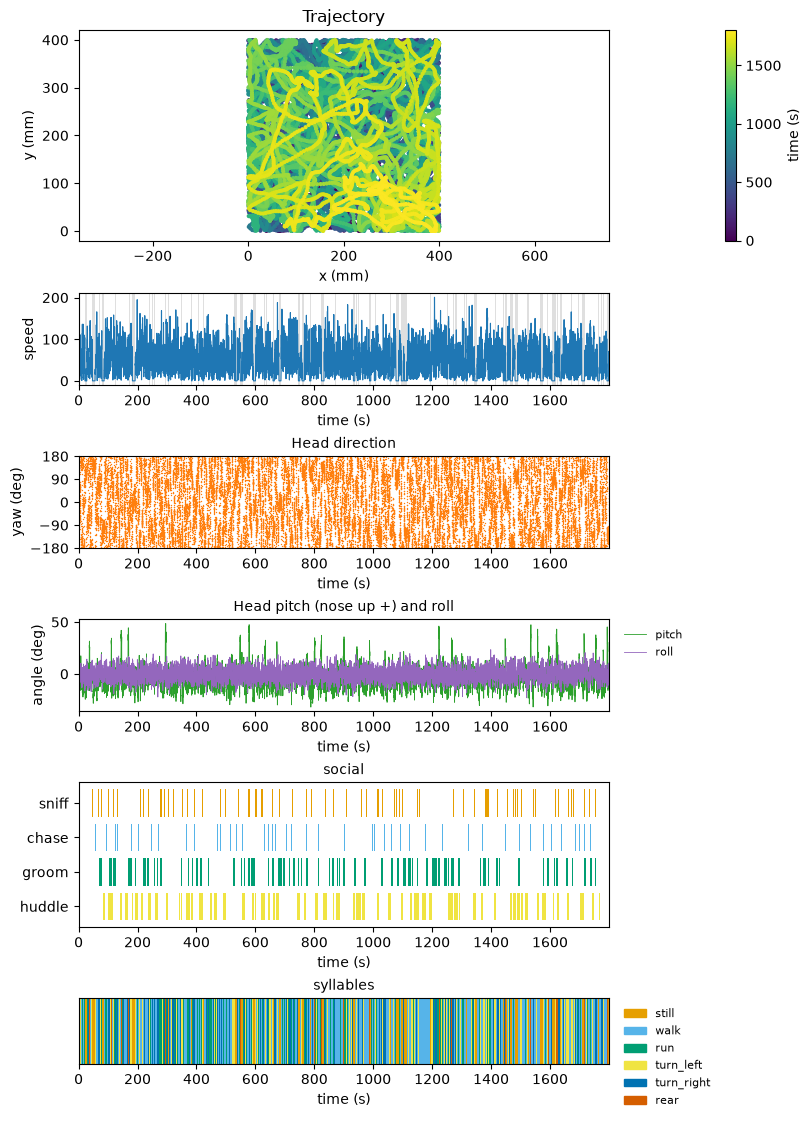

In [67]:
fig = cabana.plots.plot_behavior_overview(session)
plt.show()

## 4. Place cells

Rate maps of the 12 place cells with the highest information, then six untuned cells for contrast. Each title shows the information value and its shuffle p-value. Place cells should show a compact bright field; untuned cells show structureless noise (their maps look blotchy but nothing is above the shuffle null).

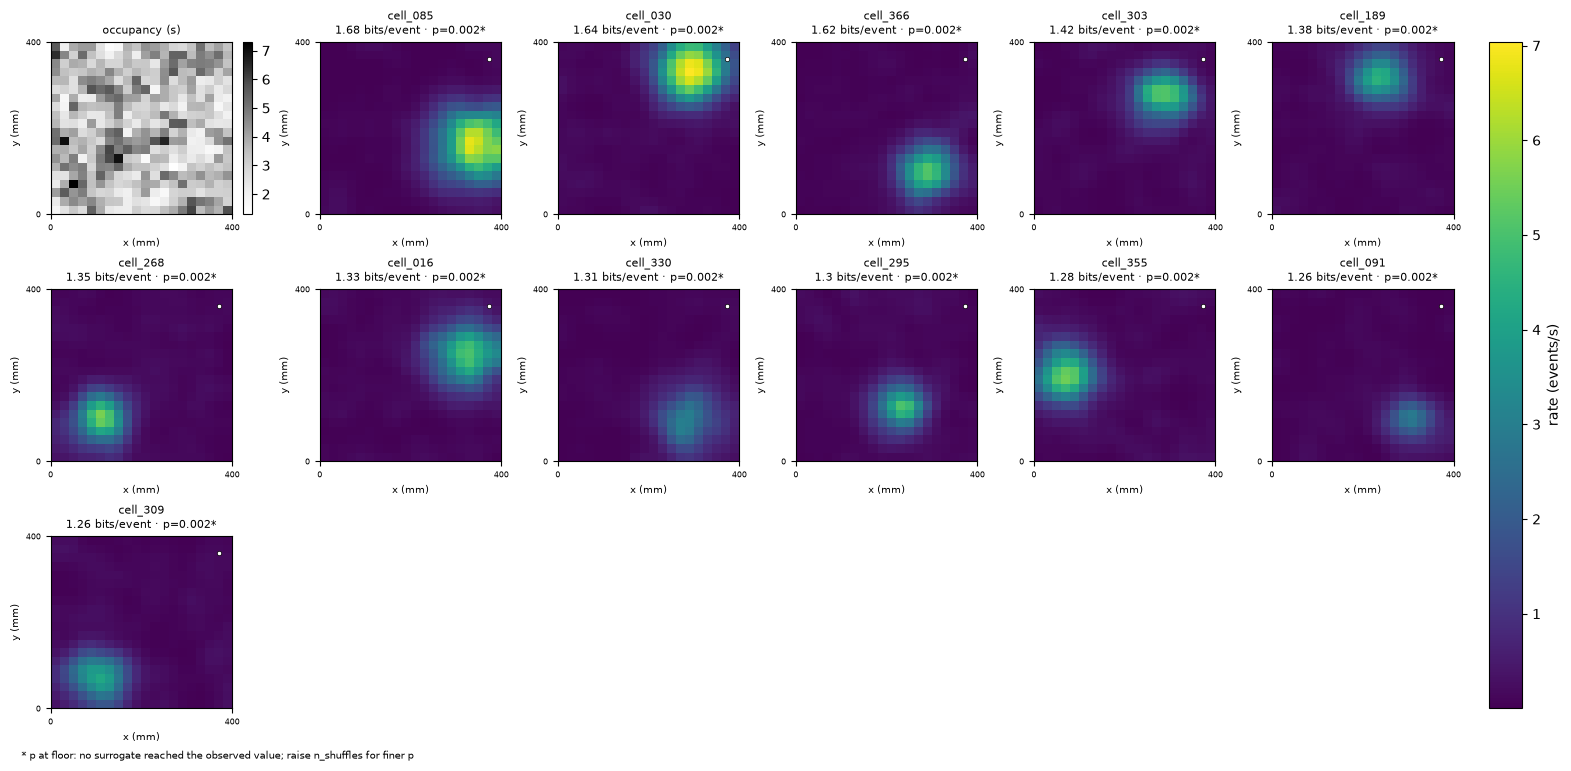

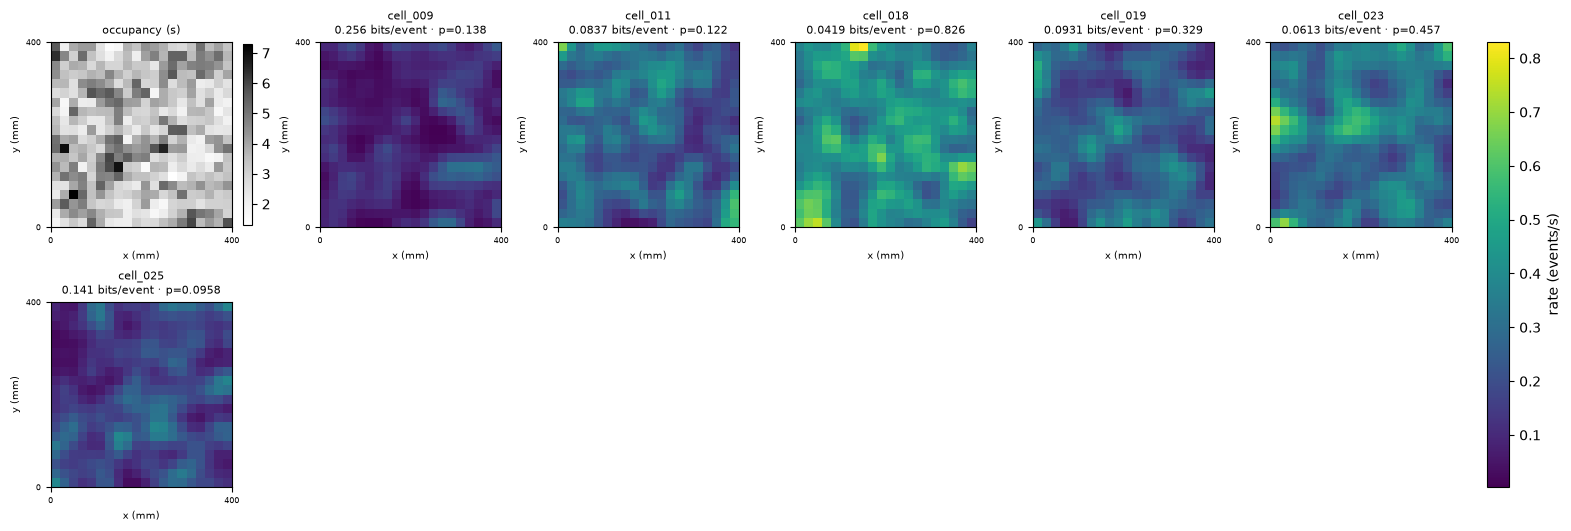

In [68]:
ic_pos = results["information_content[position]"]
place = np.array(gt["place_cells"])
untuned = np.array(gt["untuned_cells"])
top = place[np.argsort(-ic_pos.values[place])[:12]]
fig = cabana.plots.plot_rate_maps(session, ic_pos, list(top))
plt.show()
fig = cabana.plots.plot_rate_maps(session, ic_pos, list(untuned[:6]))
plt.show()

### Reading a shuffle distribution

Grey histogram: the metric recomputed on every circularly shifted copy of the cell's activity. Dashed lines: the null bounds a value must cross to be called significant. Red line: the real value. Left, a place cell is far outside its own null. Right, an untuned cell sits inside it: its information value is nonzero (information is always positive in finite data) but unremarkable.

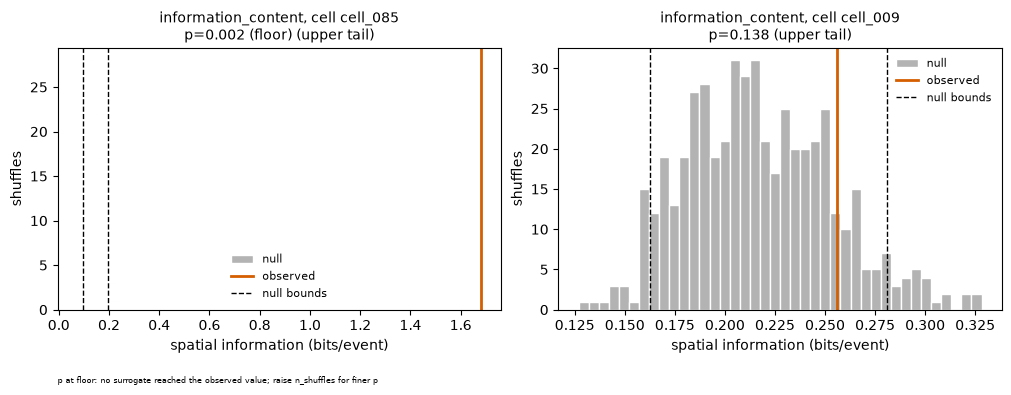

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
cabana.plots.plot_shuffle_distribution(ic_pos, int(top[0]), ax=axes[0])
cabana.plots.plot_shuffle_distribution(ic_pos, int(untuned[0]), ax=axes[1])
plt.show()

### Information vs. stability

Two different questions about the same cells: *how much* spatial information does the cell carry, and *does the same map appear in both halves of the session?* Real place cells are high on both. Points are colored by which tests each cell passed. Cells with high information but low stability would be suspect.

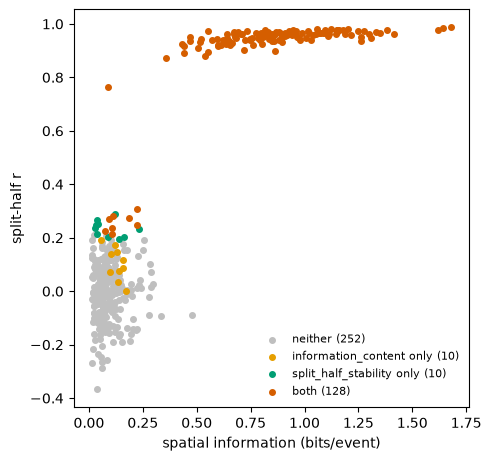

In [70]:
sh_pos = results["split_half_stability[position]"]
fig = cabana.plots.plot_metric_scatter(ic_pos, sh_pos)
plt.show()

## 5. Choosing parameters

The place-cell analyses above used `smooth_sigma_bins=1.0` because we typed it. Spatial smoothing changes which cells pass (a few percent of cells change classification between neighbouring reasonable values), so a value that is not justified is a hidden choice. CaBaNA gives three routes, and every one of them leaves the same **`Selection`** record (parameter path, value, method, criterion, candidates and their scores, the data split used, and a flag if significance was involved):

1. **Automatic rule.** A `selectors=[...]` entry in the pipeline picks a value from the data *before* the analyses run, and never sees a null or a p-value. `auto_smooth_sigma` scores each candidate sigma by how well rate maps built on four-fifths of the session (smoothed with that sigma) predict the held-out fifth, and takes the smallest sigma within one standard error of the best. `auto_null_timescale` sets the circular-shift `min_shift_s` from the autocorrelation time of the activity and the behavior.
2. **Sweep and pick.** `cabana.sweep` reruns the pipeline over a grid of values so you can *look* (rate maps, how many cells flip classification), and `SweepResult.pick` turns a sweep into a `Selection`. It refuses to pick by a p-value or a count of significant cells, because choosing the setting that makes the most cells significant biases the test in favour of that setting.
3. **User pick.** `pipe.set_param(path, value, method="user_pick", ...)` records a value you chose yourself, with a note on why.

The record travels with the results: `results.selections` lists them, and they are saved with the pipeline.

In [71]:
from cabana import sweep
from cabana import grid_bin_size, heldout_smoothing_scores

SIGMAS = [0, 0.5, 1, 1.5, 2, 3, 4]          # grid bins; 1 bin = 20 mm here
shuf_sel = ShuffleConfig(n_shuffles=100, min_shift_s=20.0, seed=0)
info = AnalysisSpec(metric={"name": "information_content"}, states="position",
                    shuffle=shuf_sel, masks=["speed"])
half = AnalysisSpec(metric={"name": "split_half_stability"}, states="position",
                    shuffle=None, masks=["speed"])

# `session` is already prepared (states and masks exist), so this pipeline is analyses only.
# No smooth_sigma_bins and no min_shift_s is typed: the selectors write them.
sel_pipe = Pipeline(
    selectors=[
        {"name": "auto_smooth_sigma", "states": "position", "candidates_bins": SIGMAS},
        {"name": "auto_null_timescale"},
    ],
    analyses=[info, half],
)
_, sel_results = sel_pipe.run(session)
pd.DataFrame(sel_results.selections)[["path", "value", "method", "criterion"]]

,path,value,method,criterion
0,analyses.information_content[position].metric....,1.5,auto_cv,heldout_poisson_loglik
1,analyses.information_content[position].shuffle...,5.0,auto_rule,autocorrelation_1_over_e
2,analyses.split_half_stability[position].metric...,1.5,auto_cv,heldout_poisson_loglik


### Route 1: the held-out score

For each candidate sigma, rate maps are built from four contiguous fifths of the session and scored on the fifth that was left out (Poisson score, summed over cells). Too little smoothing leaves noisy maps that predict badly; too much blurs real fields. The curve is plotted relative to its best point, with the standard error over folds. The **argmax** is the highest point; the **one-SE pick** is the smallest sigma statistically indistinguishable from it, which is what the selector uses (simpler maps, less risk of washing out small fields). The mm axis on top makes the choice portable across bin sizes.

argmax 1.5 bins (30 mm); one-SE pick 1.5 bins (30 mm)


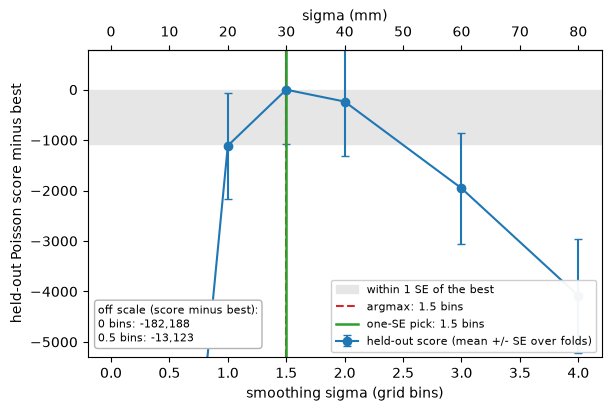

In [72]:
bin_mm, _ = grid_bin_size(session.states["position"].topology)
cands = np.asarray(SIGMAS, float)
mean, se = heldout_smoothing_scores(session, "position", cands, mask=session.valid_mask(["speed"]))
i_max = int(np.argmax(mean))
i_se = int(np.flatnonzero(mean >= mean[i_max] - se[i_max]).min())
d = mean - mean[i_max]
print(f"argmax {cands[i_max]:g} bins ({cands[i_max] * bin_mm:g} mm); "
      f"one-SE pick {cands[i_se]:g} bins ({cands[i_se] * bin_mm:g} mm)")

fig, ax = plt.subplots(figsize=(6.0, 4.0), layout="constrained")
ylo = 1.3 * np.sort(d)[2]                    # zoom past the far worse smallest candidates
ax.axhspan(-se[i_max], 0, color="0.9", label="within 1 SE of the best")
ax.errorbar(cands, d, yerr=se, fmt="o-", capsize=3, label="held-out score (mean +/- SE over folds)")
ax.axvline(cands[i_max], color="C3", ls="--", label=f"argmax: {cands[i_max]:g} bins")
ax.axvline(cands[i_se], color="C2", lw=1.8, label=f"one-SE pick: {cands[i_se]:g} bins")
off = [f"{x:g} bins: {y:,.0f}" for x, y in zip(cands, d) if y < ylo]
ax.text(0.02, 0.04, "off scale (score minus best):\n" + "\n".join(off), transform=ax.transAxes,
        fontsize=8, va="bottom", bbox={"boxstyle": "round", "fc": "white", "ec": "0.7"})
ax.set_ylim(ylo, 0.15 * abs(ylo))
ax.set_xlabel("smoothing sigma (grid bins)")
ax.set_ylabel("held-out Poisson score minus best")
ax.secondary_xaxis("top", functions=(lambda v: v * bin_mm, lambda v: v / bin_mm)).set_xlabel("sigma (mm)")
ax.legend(fontsize=8, loc="lower right", framealpha=0.95)
plt.show()

### Route 2: look at one cell across sigma

`sweep(..., shuffle=False)` strips the shuffles, so it returns observed values only and takes a fraction of a second. The gallery shows the strongest planted place cell at four sigmas on a shared colour scale. With no smoothing the map is a few bright pixels; a moderate sigma recovers the compact field; too much dissolves it (and the information value falls with it).

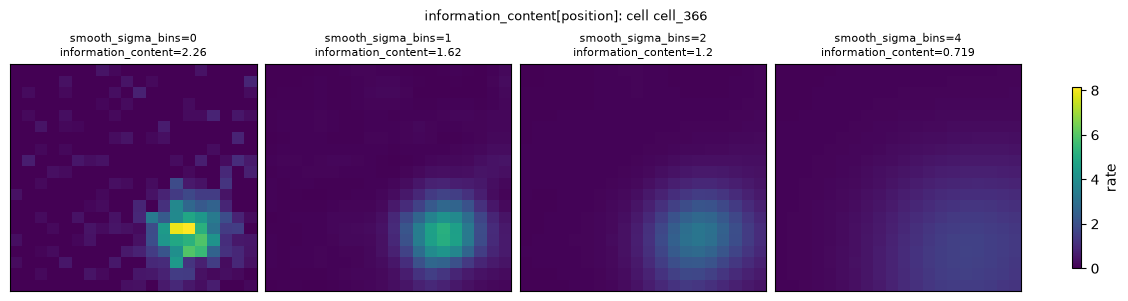

In [73]:
KEY = "analyses.*.metric.smooth_sigma_bins"
gal = sweep(session, Pipeline(analyses=[info]), {KEY: [0, 1, 2, 4]}, shuffle=False)
base = Pipeline(analyses=[info]).run(session)[1]["information_content[position]"]
cell = int(place[np.argmax(base.values[place])])
fig = cabana.plots.plot_sweep_gallery(session, gal, cell, param=KEY)
plt.show()

### How many cells flip classification across sigma?

Now the same sweep **with** the shuffle test (100 shuffles at each of seven sigmas). The left panel is the fraction of cells called significant at each sigma; it looks flat. The middle panel shows why a flat total is not reassuring: each row is a cell, and several cells switch in and out as sigma changes. `stability()` counts those flips per cell. Joining that table with the simulator's ground truth shows which cells are the unstable ones.

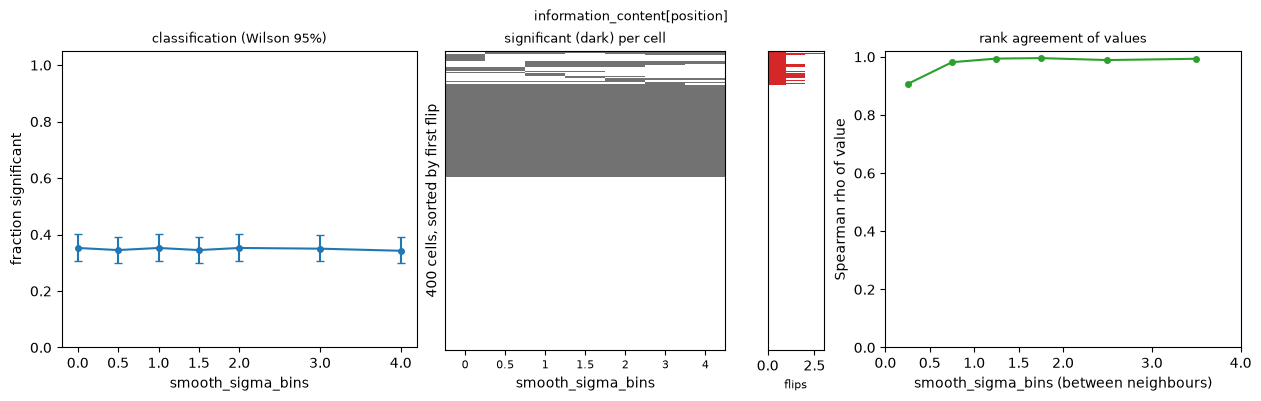

{'n_units': 400, 'n_unstable': 46, 'frac_unstable': 0.115, 'spearman_mean': 0.977}


,unstable,cells
planted,,
other,30,180
place,0,120
untuned,16,100


In [74]:
sw = sweep(session, Pipeline(analyses=[info, half]), {KEY: SIGMAS})
fig = cabana.plots.plot_sweep_stability(sw, analysis="information_content[position]", param=KEY)
plt.show()

cells, overall = sw.stability("information_content[position]")
print({k: round(v, 3) if isinstance(v, float) else v for k, v in overall.items() if k != "spearman_by_pair"})
ids = [str(c) for c in session.cell_ids]
cells["planted"] = cells["cell_id"].astype(str).map(ids.index).map(
    lambda i: "place" if i in set(gt["place_cells"]) else "untuned" if i in set(gt["untuned_cells"]) else "other")
cells.groupby("planted")["unstable"].agg(["sum", "count"]).rename(columns={"sum": "unstable", "count": "cells"})

### The guard rail, and the sanctioned way to pick

A sweep can show you the number of significant cells at every sigma, but it will not let you *choose* by it. Pick by a value-based or reliability criterion, or better, by the held-out score above (raw split-half reliability rises with sigma, so on its own it always asks for more smoothing).

In [75]:
try:
    sw.pick("frac_significant")
except ValueError as e:
    print("refused:", str(e).splitlines()[0])

pick = sw.pick("median_value", analysis="split_half_stability[position]", rule="one_se")[0]
print(f"reliability pick (one-SE): sigma {pick.value:g} bins, method {pick.method}, "
      f"informed_by_significance={pick.informed_by_significance}")
print("held-out score pick (the selector):",
      [s["value"] for s in sel_results.selections if s["path"].endswith("smooth_sigma_bins")][0], "bins")
# sw.apply(sel_pipe) would write the picks into a pipeline copy; here the selector's choice stands.

refused: refusing to pick by 'frac_significant': choosing a parameter by p-values or by how many cells come out significant is a researcher degree of freedom (it biases the null test in favour of the chosen value). Use a value-based or reliability criterion such as 'median_value' or a held-out score, or pass allow_significance=True to record the pick with informed_by_significance=True.
reliability pick (one-SE): sigma 4 bins, method sweep_stability, informed_by_significance=False
held-out score pick (the selector): 1.5 bins


### The null timescale

`auto_null_timescale` read `min_shift_s` off the data in the same run: each circular-shift analysis gets a shift of three autocorrelation times of the activity and the target, floored at 5 s and capped at a quarter of the session. For the place analyses here the autocorrelation time is a fraction of a second, so they sit on the 5 s floor (see the `shuffle.min_shift_s` row of the table above, `method="auto_rule"`); on this simulator the social analyses, whose bouts last several seconds, get a longer shift. The rest of this notebook keeps the explicit `min_shift_s=20.0` it set, so the results below stay comparable with the earlier sections.

## 6. Social behavior

Each row of the heatmap is a cell, each column a behavior, color is AUROC (0.5 = no preference, red = more active during the behavior, blue = less active). Rows are sorted by their preferred behavior. White dots mark shuffle-significant cell/behavior pairs. Because AUROC compares in-state to out-of-state frames, it works with overlapping bouts and needs no "rest" state.

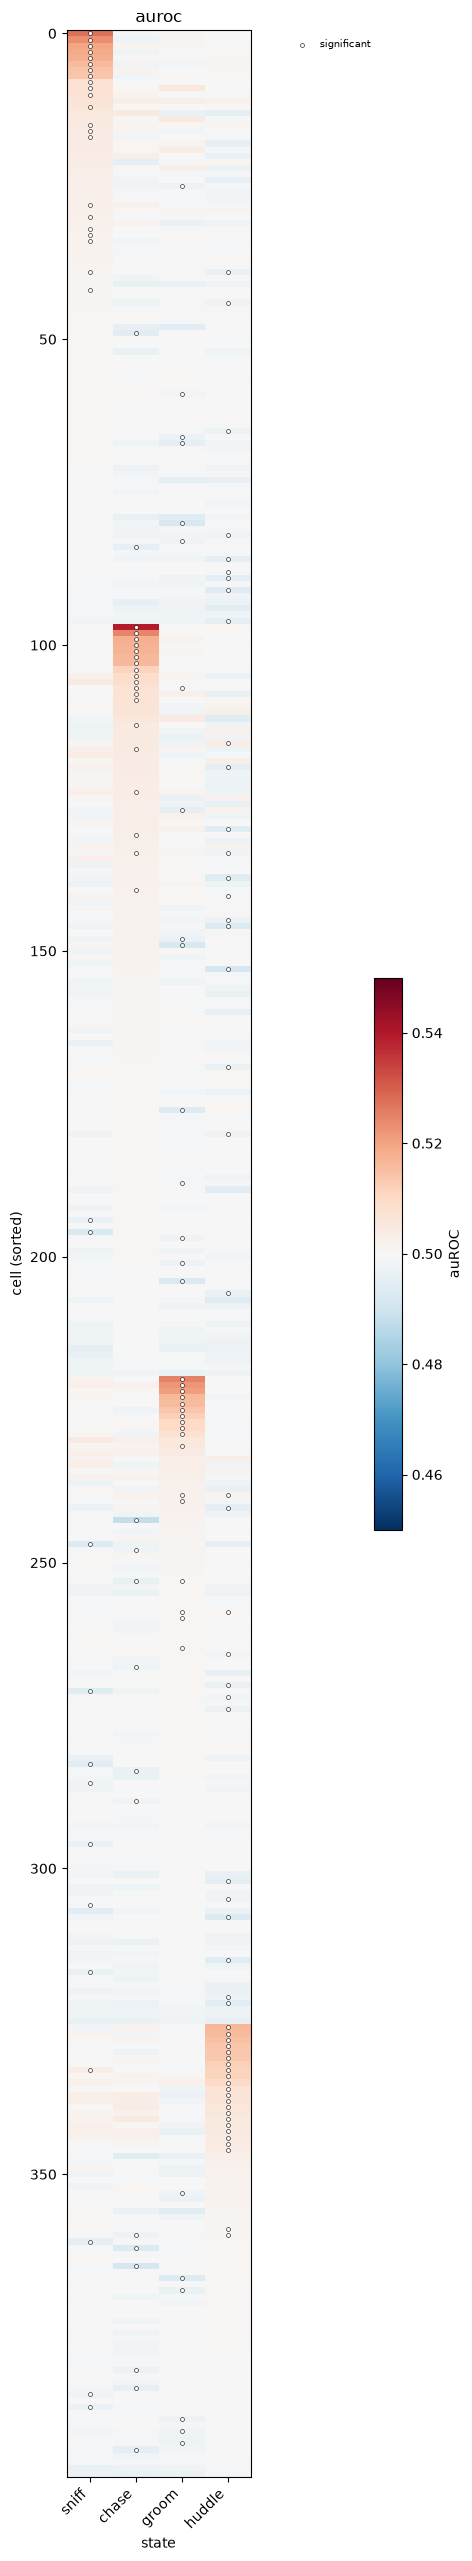

In [76]:
au_soc = results["auroc[social]"]
fig = cabana.plots.plot_tuning_heatmap(au_soc, sort_by="peak")
plt.show()

**Population-vector overlap** asks a different question: how similar is the *whole population's* activity pattern in one behavior to another? Diagonal is 1 by construction; off-diagonal values show which behaviors recruit similar vs. distinct ensembles. (No shuffle here: the overlap matrix is descriptive.)

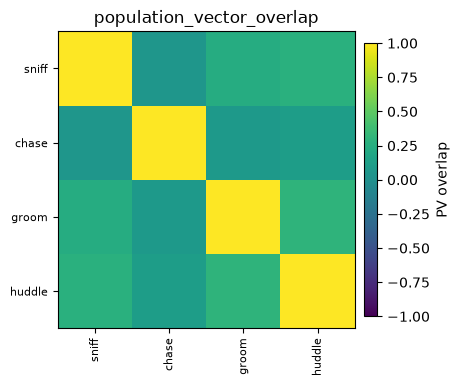

In [77]:
pvo = results["population_vector_overlap[social]"]
# circles mark state pairs whose overlap beats the circular-shift null (diagonal excluded)
fig = cabana.plots.plot_population_matrix(pvo, vmin=-1, vmax=1)
plt.show()

## 7. Syllables

**What to look for:** a bright diagonal-like band, because rows are sorted by preferred syllable: the eight planted syllable cells should stand out as red in their own column, and cells mostly mid-grey (AUROC near 0.5) are untuned. Place cells will also light up on `still`/`walk`/`run` for the reason explained in section 8.

Exactly the same plot function and the same AUROC code as the social heatmap, now with six kinematic syllables as the states.

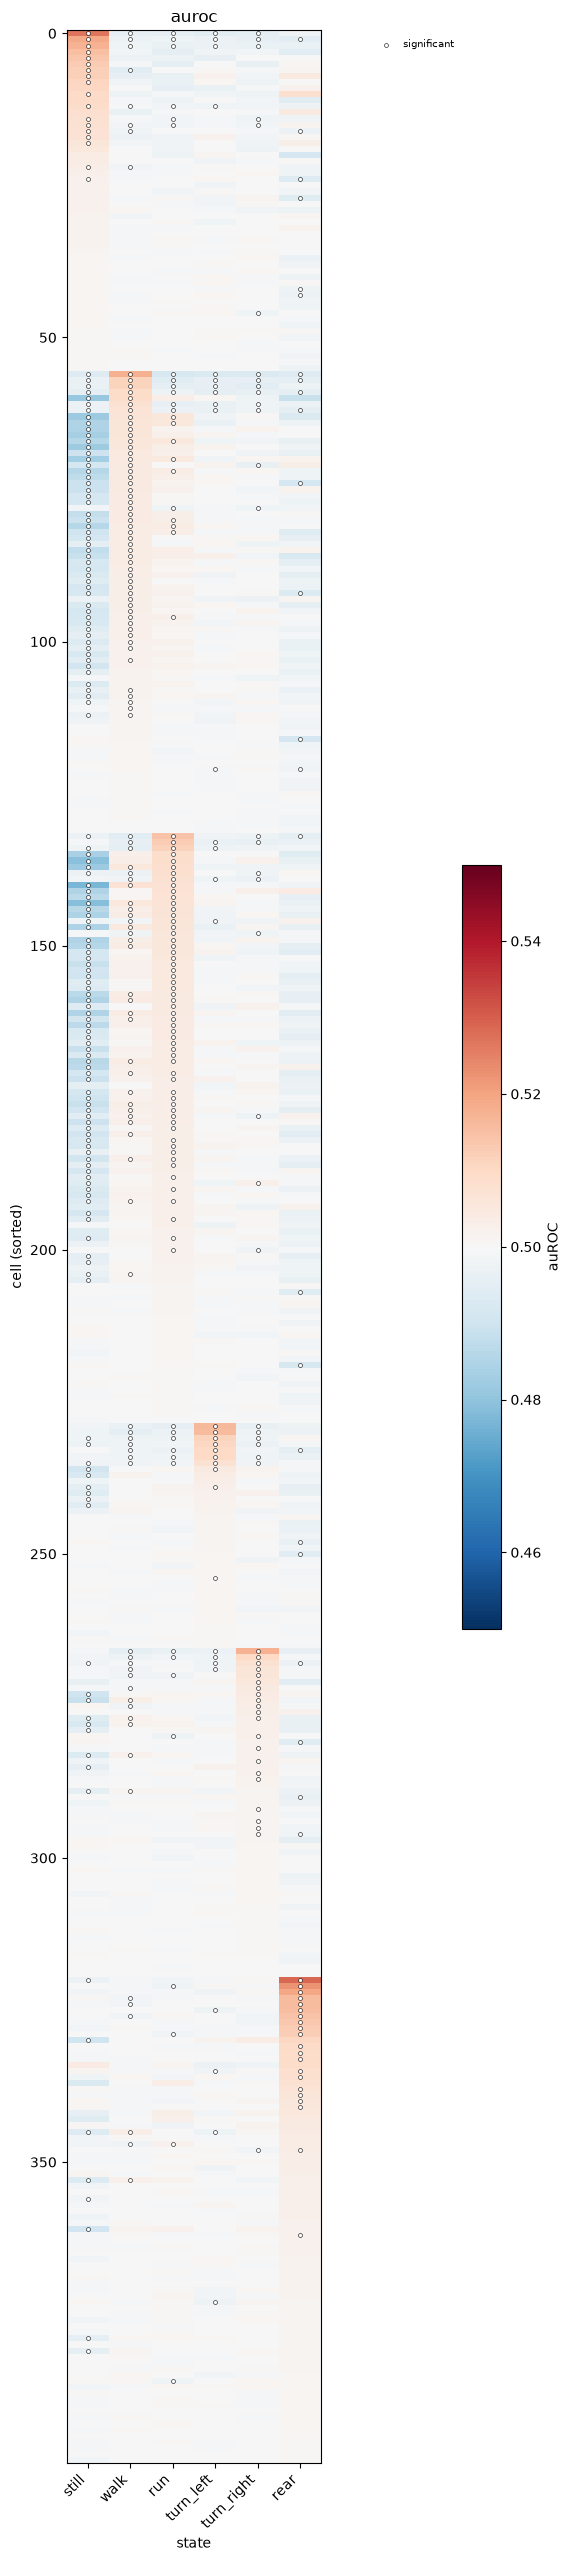

In [78]:
au_syl = results["auroc[syllables]"]
ic_syl = results["information_content[syllables]"]
fig = cabana.plots.plot_tuning_heatmap(au_syl, sort_by="peak")
plt.show()

## 8. Did we recover the truth?

For each planted population the bar shows the fraction of its cells called significant. The **untuned** bars are the false-positive rate and should sit near the dashed alpha line (or somewhat above it for multi-state results such as AUROC, where a cell counts as significant if *any* of its states is, so about 4 tests per cell for social and 6 for syllables).

One bar deserves a second look: a large fraction of **place** cells also come out significant for information content and AUROC on **syllables**. That is not a bug in the metrics, it is a real confound in the data. The simulated place cells only fire when the animal moves faster than 20 mm/s, and syllables such as `still`, `walk` and `run` are defined by speed, so a cell with a place field *is* informative about syllables. Real place cells are speed-modulated too. This is exactly the kind of thing a shared framework surfaces: the same cells, the same activity, two behavioral descriptions, and the analysis tells you they are not independent. Deciding how to disentangle them (speed as a covariate, matched-speed subsets, a joint state space) is an experimental question, not a pipeline one.

The inflated untuned bars for multi-state results are the multiple-comparison problem; section 13 shows how `ShuffleConfig(correction="max_stat")` removes most of it.

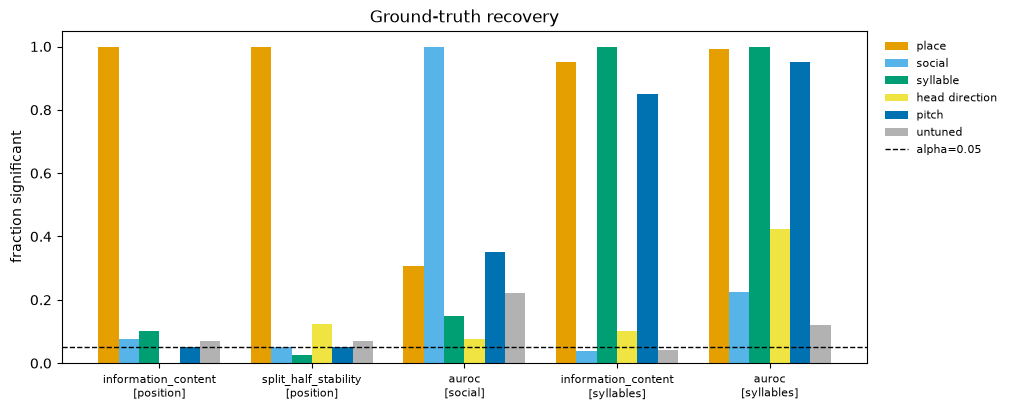

,result,population,n,fraction_significant,adjusted_fraction
0,information_content[position],place,120,1.000000,NaN
1,information_content[position],social,80,0.075000,NaN
2,information_content[position],syllable,40,0.100000,NaN
3,information_content[position],head direction,40,0.000000,NaN
4,information_content[position],pitch,20,0.050000,NaN
5,information_content[position],untuned,100,0.070000,NaN
6,split_half_stability[position],place,120,1.000000,NaN
7,split_half_stability[position],social,80,0.050000,NaN
8,split_half_stability[position],syllable,40,0.025000,NaN
9,split_half_stability[position],head direction,40,0.125000,NaN


In [79]:
fig = cabana.plots.plot_ground_truth_recovery(session, results)
summary = fig.cabana_summary
plt.show()
summary

A more specific view: for each analysis, how many *relevant* cells are detected, what is the false-positive rate in untuned cells, and, for AUROC, do cells respond in **their own planted state**, with the **right sign** (AUROC > 0.5 for excited, < 0.5 for inhibited)?

In [80]:
pops = {
    "position": ("place", list(gt["place_cells"])),
    "social": ("social", [d["cell"] for d in social]),
    "syllables": ("syllable", [d["cell"] for d in gt["syllable_cells"]]),
}
rows = []
for r in results:
    if r.level != "cell" or r.shuffle is None:
        continue
    sig = np.asarray(r.shuffle.p_value) < 0.05
    any_sig = sig if sig.ndim == 1 else sig.any(axis=1)
    pop, cells = pops[r.target]
    row = {"metric": r.metric, "target": r.target, "relevant": pop,
           "frac_sig_relevant": any_sig[cells].mean(),
           "frac_sig_untuned (FPR)": any_sig[list(gt["untuned_cells"])].mean(),
           "frac_sig_own_state": np.nan, "sign_match": np.nan}
    if r.metric == "auroc" and r.target == "social":
        ci = np.array([d["cell"] for d in social])
        own = [r.state_names.index(d["behavior"]) for d in social]
        auc = r.values[ci, own]
        excited = np.array([d["sign"] == "excited" for d in social])
        ok = np.where(excited, auc > 0.5, auc < 0.5)
        row["frac_sig_own_state"] = sig[ci, own].mean()
        row["sign_match"] = ok[sig[ci, own]].mean()
    rows.append(row)
pd.DataFrame(rows).round(2)

,metric,target,relevant,frac_sig_relevant,frac_sig_untuned (FPR),frac_sig_own_state,sign_match
0,information_content,position,place,1.0,0.07,NaN,NaN
1,split_half_stability,position,place,1.0,0.07,NaN,NaN
2,auroc,social,social,1.0,0.22,1.0,1.0
3,information_content,syllables,syllable,1.0,0.04,NaN,NaN
4,auroc,syllables,syllable,1.0,0.12,NaN,NaN


## 9. More questions about the same session

So far every analysis asked "is this cell tuned to a *state*?". Researchers also ask other things of the same data. None of them needs new loaders or a new session object: they are more `AnalysisSpec`s on the arrays we already have.

| question | analysis | target |
| --- | --- | --- |
| How does a cell respond around the *onset* of a behavior? | `peth` | a state space |
| What is the cell's mean activity in each behavior? | `mean_per_state` | a state space |
| Does the cell track a *continuous* variable such as speed? | `signal_correlation` | a signal (`signal="speed"`) |

Notice `AnalysisSpec` takes exactly one of `states=` (a state space) or `signal=` (a continuous per-frame variable). All three use the **same circular-shift null** as before. The PETH is a linear function of activity, so its null is computed exactly and fast.

PETH settings follow the survey (`docs/ANALYSIS_COVERAGE.md`): keep bouts at least 1.5 s long and at least 1 s after the previous bout, a window of -4 to +4 s around onset, baseline -4 to -1 s, response 0 to 1.5 s. The tested statistic is the mean response minus the mean baseline across events.

In [81]:
shuf = ShuffleConfig(n_shuffles=N_SHUFFLES, min_shift_s=20.0, seed=0)
extra = Pipeline(analyses=[
    AnalysisSpec(metric={"name": "mean_per_state", "statistic": "difference"},
                 states="social", shuffle=shuf),
    AnalysisSpec(metric={"name": "peth", "pre_s": 4.0, "post_s": 4.0,
                         "baseline_s": (-4.0, -1.0), "response_s": (0.0, 1.5),
                         "min_duration_s": 1.5, "min_gap_s": 1.0},
                 states="social", shuffle=shuf),
    AnalysisSpec(metric={"name": "signal_correlation", "max_lag_s": 2.0},
                 signal="speed", shuffle=shuf),
])
# the session already holds the transformed states, so only the analyses run here
session, extra_results = extra.run(session, progress=True)
for r in extra_results:
    results.add(r)
print(len(results), "results in one ResultSet")

[analyze] mean_per_state[social]
[analyze] peth[social]
[analyze] signal_correlation[speed]
10 results in one ResultSet


### Peri-event time histograms

Each panel is one behavior. Rows are cells, columns are time relative to bout onset (dashed line), color is the baseline-subtracted event average (red = above baseline). Stars at the right edge mark cells significant under the shuffle test, **not** the Wilcoxon p in the extras: events within one animal are autocorrelated, so the shuffle p is the one to use. The lower trace averages all cells (grey) and the significant cells (orange). Grey and orange bands are the baseline and response windows.

events per behavior: {'sniff': np.int64(70), 'chase': np.int64(54), 'groom': np.int64(71), 'huddle': np.int64(60)}


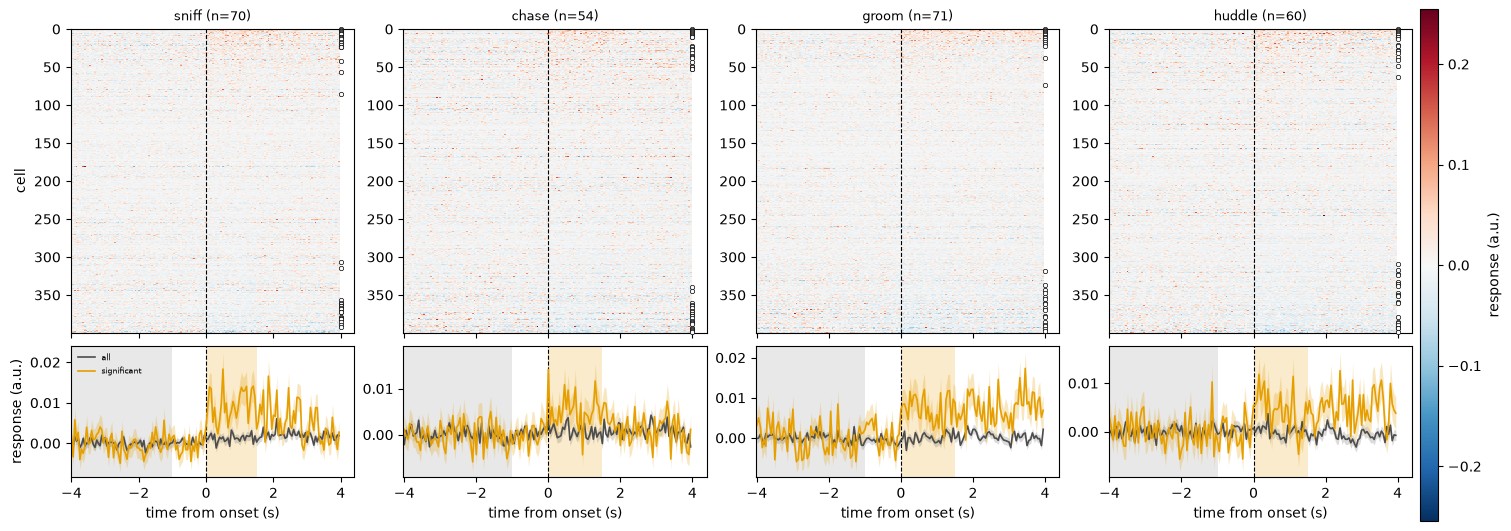

In [82]:
pe = results["peth[social]"]
print("events per behavior:", dict(zip(pe.state_names, pe.extras["n_events"])))
fig = cabana.plots.plot_peth(pe, session, ncols=4)
plt.show()

A single cell, event by event, is the sanity check behind the average: the top social cell (largest |PETH response| in its own planted behavior). The image shows every event, the trace below is their mean +/- SEM.

top social cell: 347 chase excited


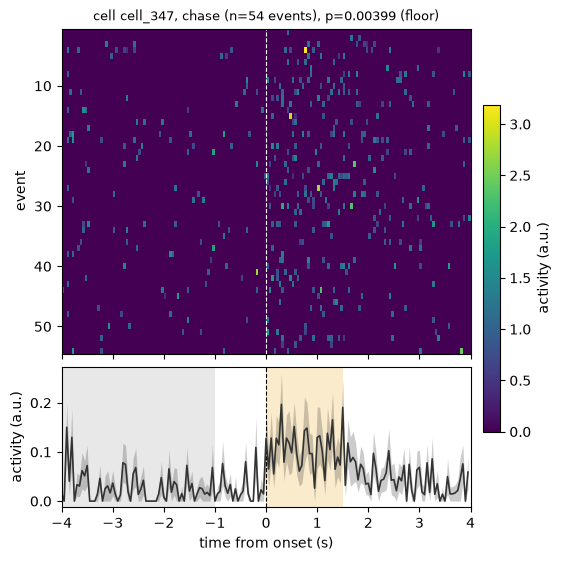

In [83]:
own = [pe.state_names.index(d["behavior"]) for d in social]
ci_soc = np.array([d["cell"] for d in social])
best = int(np.argmax(np.abs(np.nan_to_num(pe.values[ci_soc, own]))))
top_cell, top_state = int(ci_soc[best]), social[best]["behavior"]
print("top social cell:", top_cell, top_state, social[best]["sign"])
fig = cabana.plots.plot_event_raster(session, pe, top_cell, top_state,
                                     mask=session.valid_mask(["social_scored"]))
plt.show()

### Mean activity per state

`statistic="difference"` reports mean activity inside the behavior minus mean outside it, so 0 means no preference and the sign says excited or inhibited (no need to know a cell's baseline rate). Same heatmap function as AUROC; here the color is the raw difference. AUROC and mean difference agree on who responds, but the mean difference keeps the *size* of the effect in activity units, AUROC the *reliability*.

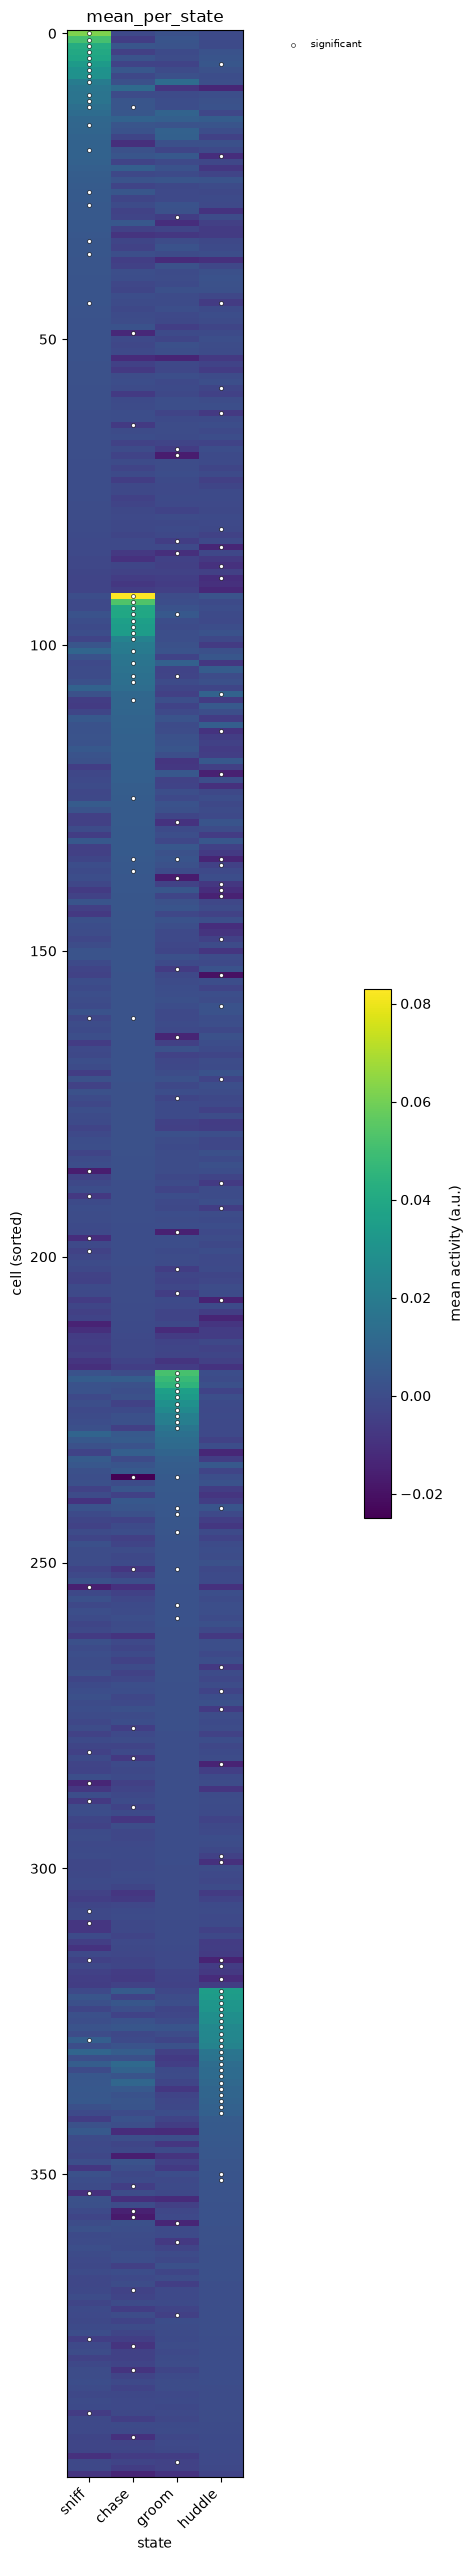

In [84]:
fig = cabana.plots.plot_tuning_heatmap(results["mean_per_state[social]"], sort_by="peak")
plt.show()

### Correlation with speed (a continuous target)

This is both a question in its own right and the standard confound check: place cells in this simulation only fire above 20 mm/s, so they should correlate with speed, while untuned cells should not. The extras also hold the cross-correlation at lags up to +/-2 s (`xcorr`, `lags_s`, `best_lag_s`; a positive best lag means the cell *follows* speed).

**What to look for:** on the left the red line should sit far out in the tail of the grey null, on the right inside it. A place cell here fires only when the animal is fast, so a significant speed correlation is expected and is the reason to check speed before calling a cell a place cell.

Left: a place cell's observed correlation (red) against its own circular-shift null. Right: an untuned cell.

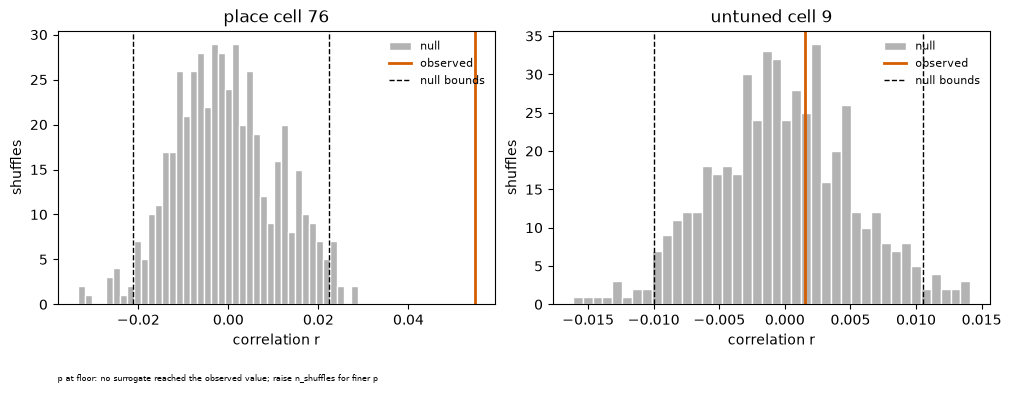

significant speed correlation: place 0.91, untuned 0.05


In [85]:
sc = results["signal_correlation[speed]"]
pc = int(place[np.nanargmax(np.abs(sc.values[place]))])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
cabana.plots.plot_shuffle_distribution(sc, pc, ax=axes[0]); axes[0].set_title(f"place cell {pc}")
cabana.plots.plot_shuffle_distribution(sc, int(untuned[0]), ax=axes[1]); axes[1].set_title(f"untuned cell {int(untuned[0])}")
plt.show()
sig_sc = sc.shuffle.significant
print(f"significant speed correlation: place {sig_sc[place].mean():.2f}, untuned {sig_sc[untuned].mean():.2f}")

## 10. Population analyses on re-binned data

PCA, decoding and GLMs work on a coarser clock (100 ms to 1 s) than the 20 Hz frames. `rebin_time` is a preprocess step that resamples **everything on the neural clock together**: activity is summed (events) or averaged (dF/F), masks and states are resampled by occupancy fraction (the share of the new bin that the animal spent in that state), signals are averaged. After it the session has fewer frames (`n_time` changes) and `fs` changes accordingly, but remains a normal session, so the *same* `AnalysisSpec` machinery applies.

This **second pipeline** runs on the session returned by the first one (so it already has the state spaces):

1. `rebin_time(bin_s=0.5)`
2. `design_matrix(states=["social"], signals=["speed"], basis=...)`: the regressors for the GLM. Each social state is convolved with 4 raised-cosine bumps (smooth, overlapping bump-shaped time kernels) spanning 1 s before to 3 s after the state (so a response that *follows* or *anticipates* the behavior can be captured), and speed enters as a standardized covariate.

Analyses:

- `pca_population`: distances between the mean population vectors of each social state (in z-scored population space).
- `decode_states`: a cross-validated linear decoder of each behavior from the population. **Folds are contiguous blocks of time** (block cross-validation: train on some blocks, test on a held-out one), never random frames, because neighboring frames are nearly identical; random folds would leak and inflate accuracy.
- `glm_encoding`: a Poisson regression per cell on the design matrix (fitted by iteratively reweighted least squares, IRLS, a standard way to fit generalized linear models), again block cross-validated. For each regressor *group* (one behavior, or speed) it reports the **unique contribution**: how much held-out deviance explained is lost when that group is removed.

### Why a different null here

Shifting each cell's activity separately is the right null for single-cell tuning. For population questions the question is about the *labels*: do the behavior labels carry population structure beyond what a label sequence with the same autocorrelation would give? So these analyses use `label_shuffle`, which permutes the behavior in blocks of `block_s` seconds while activity stays put. It is a one-line change in the `ShuffleConfig`: `null={"name": "label_shuffle", "block_s": 5.0}`.

In [86]:
null = {"name": "label_shuffle", "block_s": 5.0}
pop_pipe = Pipeline(
    preprocess=[
        {"name": "rebin_time", "bin_s": 0.5},
        {"name": "design_matrix", "states": ["social"], "signals": ["speed"],
         "basis": {"n_basis": 4, "pre_s": 1.0, "post_s": 3.0}},
    ],
    analyses=[
        AnalysisSpec(metric={"name": "pca_population"}, states="social",
                     shuffle=ShuffleConfig(n_shuffles=100, null=null, seed=0)),
        AnalysisSpec(metric={"name": "decode_states"}, states="social",
                     shuffle=ShuffleConfig(n_shuffles=30, null=null, seed=0)),
        AnalysisSpec(metric={"name": "glm_encoding"}, signal="design", masks=["social_scored"],
                     shuffle=None),
    ],
)
t0 = time.perf_counter()
binned, pop_results = pop_pipe.run(session, progress=True)
print(f"{session.n_time} frames at {session.fs:g} Hz -> {binned.n_time} frames at {binned.fs:g} Hz; "
      f"{time.perf_counter() - t0:.1f} s")
print("design columns:", cabana.design_columns(binned)[:6], "...", len(cabana.design_columns(binned)), "total")

[preprocess] rebin_time
[preprocess] design_matrix
[analyze] pca_population[social]
[analyze] decode_states[social]
[analyze] glm_encoding[design]
36000 frames at 20 Hz -> 3600 frames at 2 Hz; 50.9 s
design columns: ['social:sniff@0', 'social:sniff@1', 'social:sniff@2', 'social:sniff@3', 'social:chase@0', 'social:chase@1'] ... 17 total


### PCA: how far apart are the behaviors in population space?

Matrix of pairwise distances between the mean population vectors of the social states. A large entry means the whole population is in a clearly different pattern in the two behaviors. Whether these distances are *bigger than expected for arbitrary labels* is what the label-shuffle null (stored in `pca.shuffle`) answers.

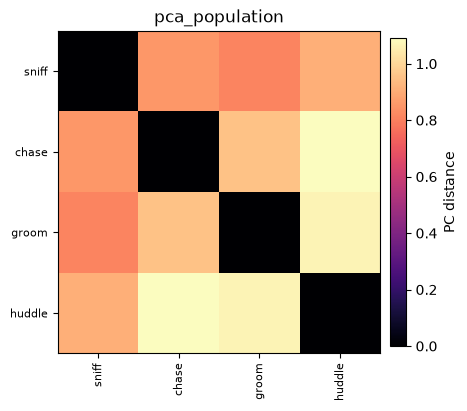

In [87]:
pca = pop_results["pca_population[social]"]
fig = cabana.plots.plot_population_matrix(pca, cmap="magma")
plt.show()

### Decoding against its null

Bars: balanced accuracy of a one-vs-rest decoder per behavior on held-out time blocks (chance = 0.5). Black ticks: the 95th percentile of the accuracy obtained with block-shuffled labels. A bar above its tick means the population carries information about that behavior beyond label autocorrelation.

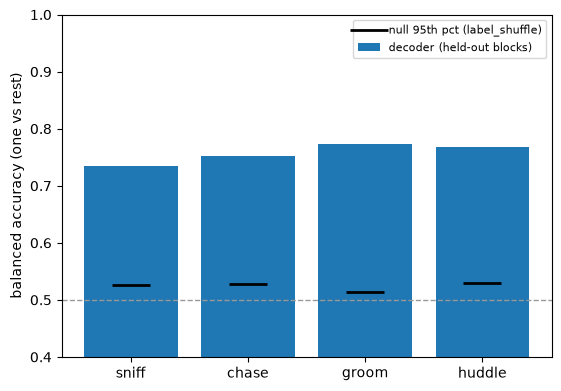

,state,balanced_acc,null_hi,p
0,sniff,0.736,0.526,0.032
1,chase,0.752,0.527,0.032
2,groom,0.774,0.515,0.032
3,huddle,0.768,0.530,0.032


In [88]:
dec = pop_results["decode_states[social]"]
fig, ax = plt.subplots(figsize=(5.5, 3.8), layout="constrained")
xs = np.arange(len(dec.state_names))
ax.bar(xs, dec.values, color="C0", label="decoder (held-out blocks)")
ax.plot(xs, dec.shuffle.null_hi, "k_", ms=28, mew=2, label="null 95th pct (label_shuffle)")
ax.axhline(0.5, color="0.6", ls="--", lw=1)
ax.set_xticks(xs, dec.state_names); ax.set_ylim(0.4, 1.0)
ax.set_ylabel("balanced accuracy (one vs rest)"); ax.legend(fontsize=8)
plt.show()
pd.DataFrame({"state": dec.state_names, "balanced_acc": dec.values,
              "null_hi": dec.shuffle.null_hi, "p": dec.shuffle.p_value}).round(3)

### GLM: which regressor does each cell need?

For each cell the GLM asks which behavior (or speed) is *uniquely* needed to predict it on held-out time. Below, for each planted social cell: is its top group its own behavior? And for place cells: is it speed? (The GLM sees speed and the social states together, so a cell is credited to speed only to the extent that speed adds information the behaviors do not.)

regressor groups: ['social:sniff', 'social:chase', 'social:groom', 'social:huddle', 'speed']
social cells whose top group is their own behavior: 0.99
place cells whose top group is speed:               0.89
median held-out deviance explained: social 0.042, untuned -0.014


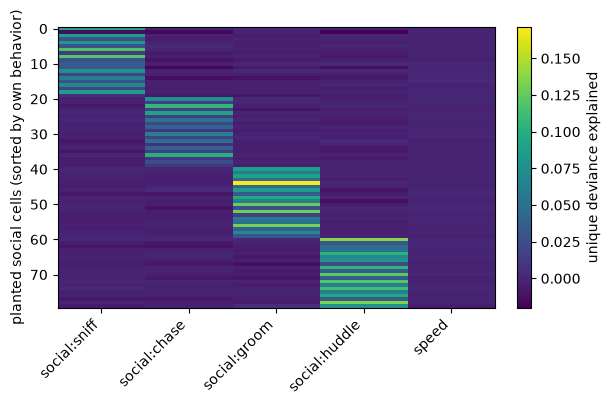

In [89]:
glm = pop_results["glm_encoding[design]"]
groups = [str(g) for g in glm.extras["group_names"]]
top = np.nanargmax(glm.values, axis=1)
want = np.array([groups.index(f"social:{d['behavior']}") for d in social])
print("regressor groups:", groups)
print(f"social cells whose top group is their own behavior: {np.mean(top[ci_soc] == want):.2f}")
print(f"place cells whose top group is speed:               {np.mean(top[place] == groups.index('speed')):.2f}")
de = glm.extras["deviance_explained"]
print(f"median held-out deviance explained: social {np.nanmedian(de[ci_soc]):.3f}, untuned {np.nanmedian(de[untuned]):.3f}")
fig, ax = plt.subplots(figsize=(6, 3.8), layout="constrained")
order = np.argsort(want, kind="stable")
im = ax.imshow(glm.values[ci_soc][order], aspect="auto", cmap="viridis")
ax.set_xticks(range(len(groups)), groups, rotation=45, ha="right")
ax.set_ylabel("planted social cells (sorted by own behavior)")
fig.colorbar(im, ax=ax, label="unique deviance explained")
plt.show()

## 11. Amplitude: mutual information

A rate map collapses the activity in each state to one number, its mean. But a cell can carry information in *how much* it fires, not only in *where*: discretise the amplitude into a few levels and the tuning curve becomes a **state x level histogram**, p(level | state). **Mutual information (MI)** between state and level is a single number over that histogram, and it picks up whatever the amplitude distribution says.

Because deconvolved activity is dominated by zeros, even a cell whose amplitude says nothing beyond "the animal is in the field" has most of every column in the lowest level. So look at p(level | state) and at the **lift**, log2 of p(level | state) / p(level), which is zero wherever a state looks like the overall distribution. MI is the average of that lift. (An optional Miller-Madow correction removes the textbook first-order sampling bias of the plug-in estimate; it is off by default because the shuffle null carries the same bias.)


In [90]:
shuf_mi = ShuffleConfig(n_shuffles=200, min_shift_s=20.0, seed=0)
# two analyses with the same metric and target: the second gets an explicit name
mi_pipe = Pipeline(analyses=[
    AnalysisSpec(metric={"name": "mutual_information"}, states="position",
                 shuffle=shuf_mi, masks=["speed"]),                       # 5 quantile levels
    AnalysisSpec(name="mutual_information_binary[position]",
                 metric={"name": "mutual_information", "binning": "binary"},
                 states="position", shuffle=shuf_mi, masks=["speed"]),    # on / off only
])
t0 = time.perf_counter()
_, mi_res = mi_pipe.run(session)
mi_pos = mi_res["mutual_information[position]"]
mi_bin = mi_res["mutual_information_binary[position]"]
print(f"{time.perf_counter() - t0:.1f} s")

sig = {"Skaggs information": ic_pos.shuffle.p_value < 0.05,
       "MI, 5 quantile levels": mi_pos.shuffle.p_value < 0.05,
       "MI, binary (on/off)": mi_bin.shuffle.p_value < 0.05}
pd.DataFrame({"detect_place": {k: v[place].mean() for k, v in sig.items()},
              "FPR_untuned": {k: v[untuned].mean() for k, v in sig.items()}}).round(2)


63.5 s


,detect_place,FPR_untuned
Skaggs information,1.0,0.07
"MI, 5 quantile levels",1.0,0.03
"MI, binary (on/off)",1.0,0.01


Two ways to look at the histogram of the three planted place cells with the most MI. Left to right within a row are the activity levels (lowest to highest); each map shows, for one level, how likely that level is at every location. **Conditional** shows p(level | location): the lowest level is everywhere, and the higher levels light up inside the field. **Lift** removes the overall level frequencies: red means the level is over-represented there, blue under-represented. An untuned cell (last row) has a flat lift map: its amplitude says nothing about location.

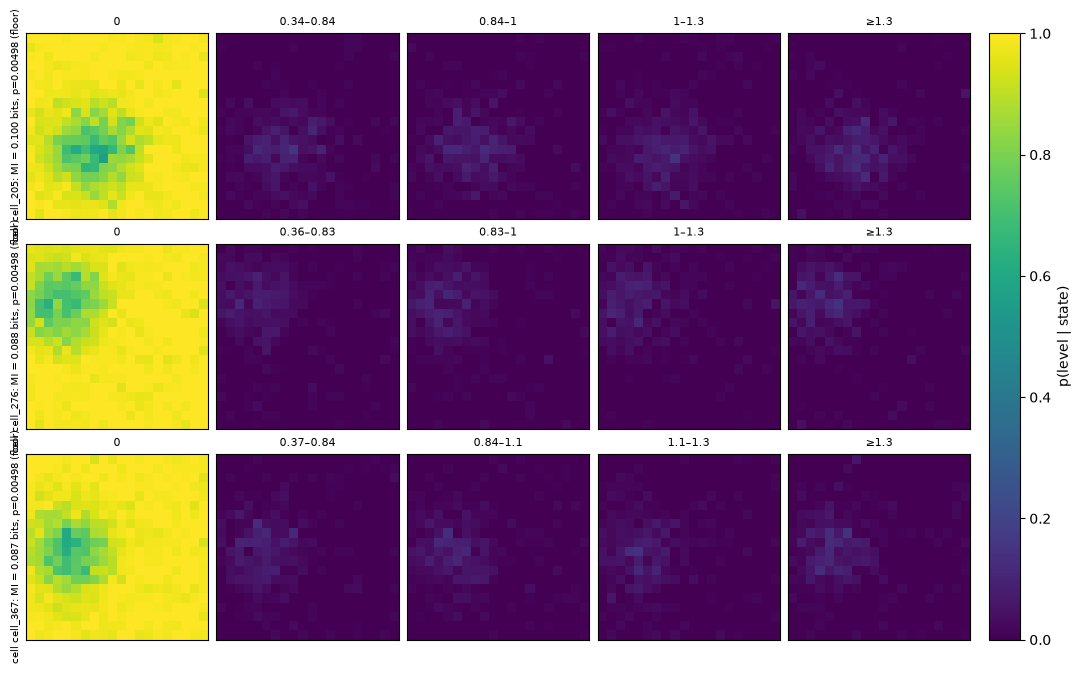

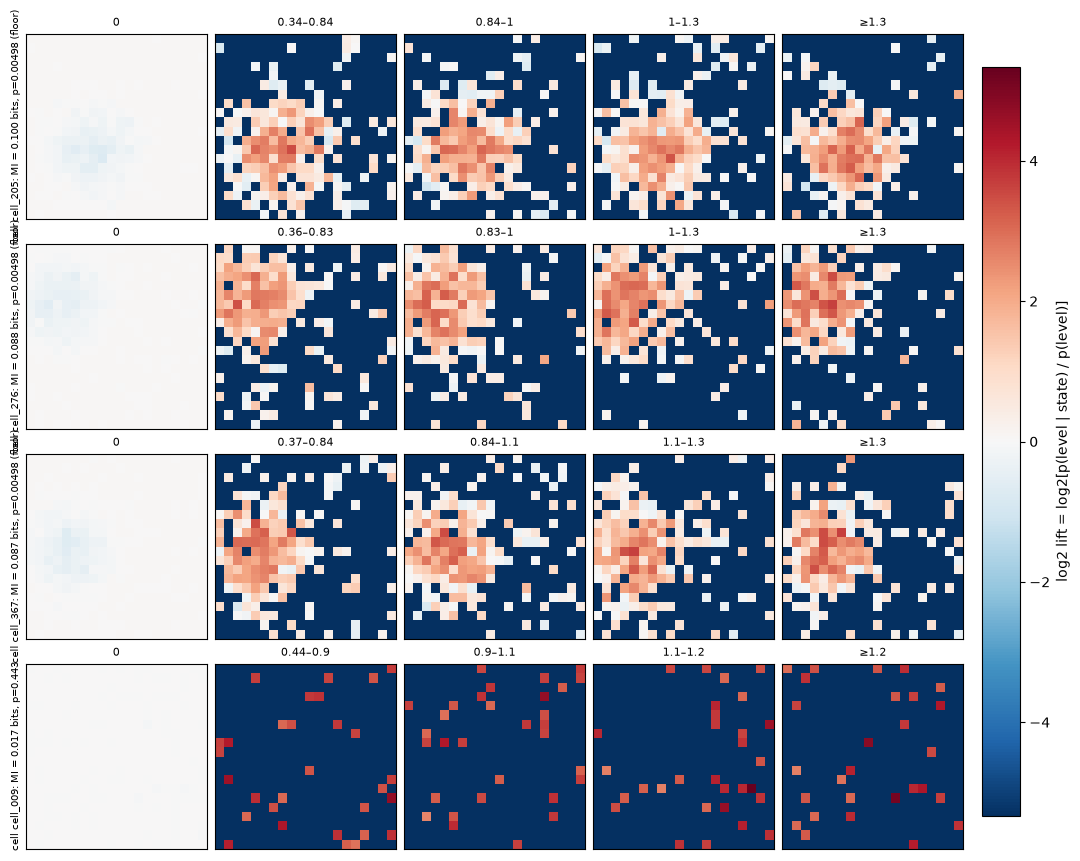

In [91]:
top3 = place[np.argsort(-np.nan_to_num(mi_pos.values[place]))[:3]]
pos_states = session.states["position"]
fig = cabana.plots.plot_joint_histogram(mi_pos, list(top3), states=pos_states, normalize="conditional")
plt.show()
fig = cabana.plots.plot_joint_histogram(mi_pos, [*top3, int(untuned[0])], states=pos_states, normalize="lift")
plt.show()

### Skaggs information versus MI

Both are measured in bits and both are compared with the same circular-shift null, so each axis is shown minus its null mean. Place cells (black rings) rise on both; the question is whether MI finds cells that Skaggs information misses or the other way around. On the default seed neither finds cells the other misses: the planted cells change *where* they fire, not how strongly, so the extra amplitude detail adds no detections and, as the sweep below shows, costs power on short recordings.

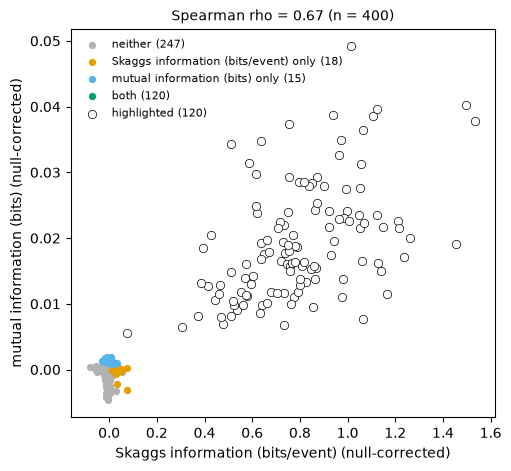

In [92]:
fig = cabana.plots.plot_information_comparison(
    ic_pos, mi_pos, labels=("Skaggs information (bits/event)", "mutual information (bits)"),
    highlight=list(place))
plt.show()

### Why this is safe: the null carries the same bias

With 400 location bins and several levels, the histogram has thousands of cells and a recording only fills a few of them, so the *observed* MI is biased upward. That does not produce false positives, because every circularly shifted copy of the cell has the same finite-sampling bias; the null is shifted up by the same amount. The price is power: more levels means fewer samples per histogram cell. The sweep below (reduced settings: 80 cells, 50 shuffles) varies the number of levels and the recording duration. Solid lines are MI, dashed is Skaggs information (which does not use levels, so it is flat). Read it as: the false-positive rate (right) should stay near the dashed 0.05 line for every setting, while detection (left) falls as levels grow and recovers with longer recordings.

5.2 s


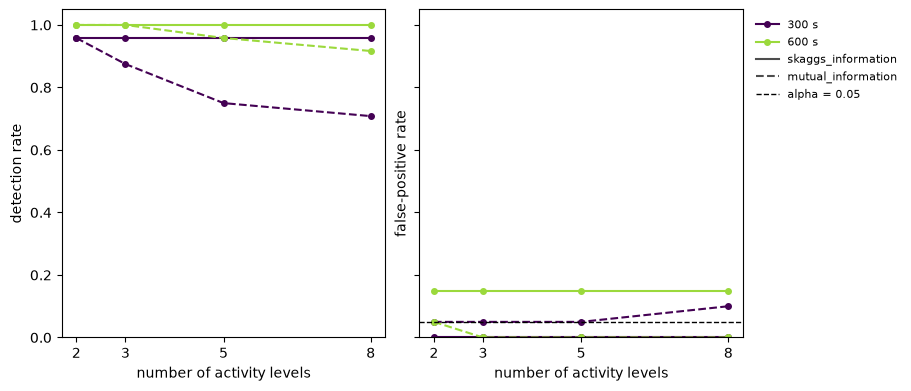

In [93]:
def levels_sweep(durations=(300.0, 600.0), levels=(2, 3, 5, 8), n_shuf=50):
    shuf = ShuffleConfig(n_shuffles=n_shuf, min_shift_s=20.0, seed=0)
    prep = Pipeline(transforms=pipe.transforms, preprocess=pipe.preprocess, analyses=[])
    rows = []
    for dur in durations:
        sess, _ = prep.run(simulate_session(duration_s=dur, n_cells=80, seed=0))
        g = sess.meta["ground_truth"]
        rel, unt = list(g["place_cells"]), list(g["untuned_cells"])
        runs = [("skaggs_information", None, {"name": "information_content", "smooth_sigma_bins": 1.0})]
        runs += [("mutual_information", k, {"name": "mutual_information", "n_levels": k}) for k in levels]
        for label, k, metric in runs:
            spec = AnalysisSpec(metric=metric, states="position", shuffle=shuf, masks=["speed"])
            _, res = Pipeline(analyses=[spec]).run(sess)
            p = np.asarray(res.get(metric["name"], "position").shuffle.p_value)
            for kk in ([k] if k else levels):    # Skaggs does not depend on levels: repeat as a flat line
                rows.append({"metric": label, "n_levels": kk, "duration_s": dur,
                             "detection": (p[rel] < 0.05).mean(), "fpr": (p[unt] < 0.05).mean()})
    return pd.DataFrame(rows)

t0 = time.perf_counter()
sweep = levels_sweep()
print(f"{time.perf_counter() - t0:.1f} s")
fig = cabana.plots.plot_level_sweep(sweep)
plt.show()

## 12. Bayesian decoder

Turn the question around: given the population's activity at one moment, *where is the animal*? A **naive-Bayes** decoder treats cells as independent given the state: it multiplies, over cells, the likelihood of each cell's current activity given each location, then picks the most probable location. The state x level histogram above is exactly such a likelihood table (the `empirical` option); the Gaussian option (the Bayesian decoder of Shuman et al. 2020, *Nat Neurosci*) and the Poisson option fit a parametric likelihood per location instead. Held-out blocks are decoded by a model that never saw them, and the null is the same `label_shuffle` used for population decoding earlier. Errors are in mm; chance is always guessing the most occupied bin.

Position decoders here score a **1 s window** of activity (`window_s=1.0`). With 400 bins and only about 47 moving frames per bin, a 0.25 s window occasionally matches a sparsely visited corner bin and decodes the frame hundreds of mm away; the longer window mostly removes that.


15.6 s
          median error (mm)  chance error (mm)  median p over states
gaussian               40.0             188.68                 0.048
poisson                20.0             188.68                 0.048


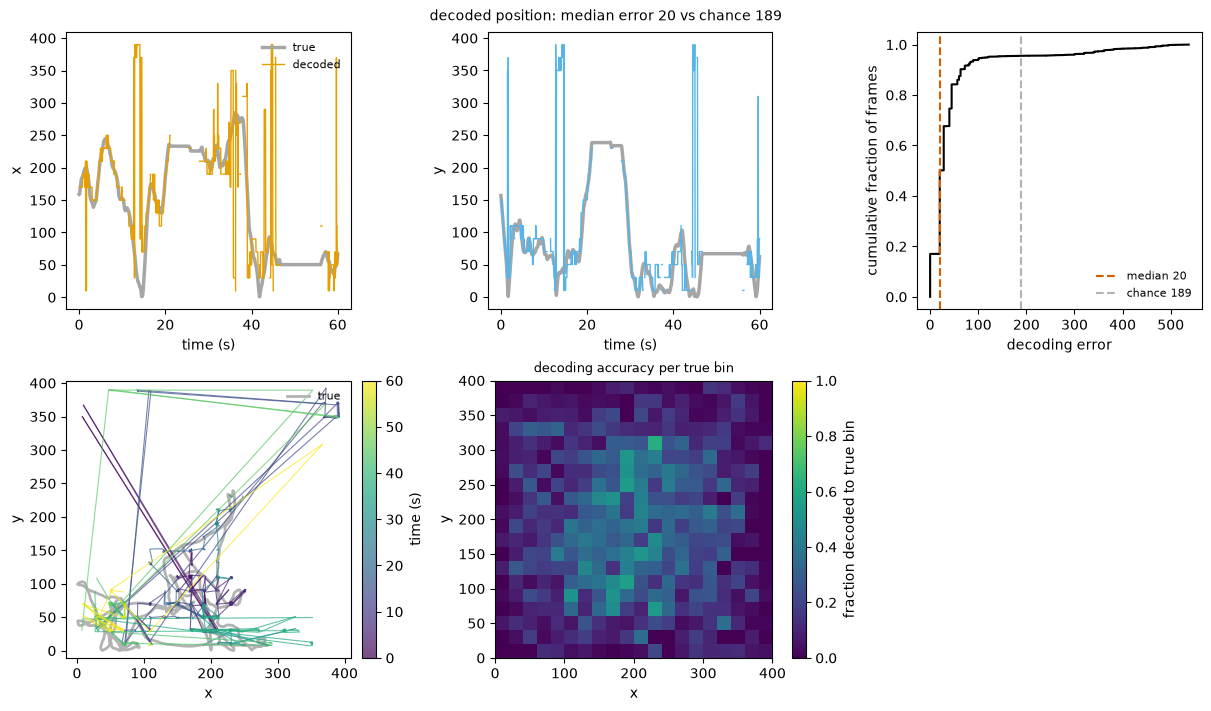

In [94]:
null = {"name": "label_shuffle", "block_s": 5.0}
dec_shuf = ShuffleConfig(n_shuffles=20, null=null, seed=0)
dec = {}
t0 = time.perf_counter()
for lik in ("gaussian", "poisson"):   # gaussian = Shuman 2020 (per-state sigma)
    spec = AnalysisSpec(metric={"name": "bayesian_decoder", "likelihood": lik,
                                "smooth_sigma_bins": 1.0, "window_s": 1.0},
                        states="position", shuffle=dec_shuf, masks=["speed"])
    dec[lik] = Pipeline(analyses=[spec]).run(session)[1]["bayesian_decoder[position]"]
print(f"{time.perf_counter() - t0:.1f} s")
print(pd.DataFrame({k: {"median error (mm)": r.extras["error_overall"][0],
                        "chance error (mm)": r.extras["chance_error"][0],
                        "median p over states": np.nanmedian(r.shuffle.p_value)}
                    for k, r in dec.items()}).round(3).T)
fig = cabana.plots.plot_decoded_trajectory(dec["poisson"], session, pos_states)
plt.show()


**What to look for:** each curve is the distribution of per-frame decoding errors. A good decoder has most of its mass far left of the dotted chance line, with a short tail; the dashed lines mark the medians. A second bump near the chance error means some frames are decoded to a wrong, distant bin.


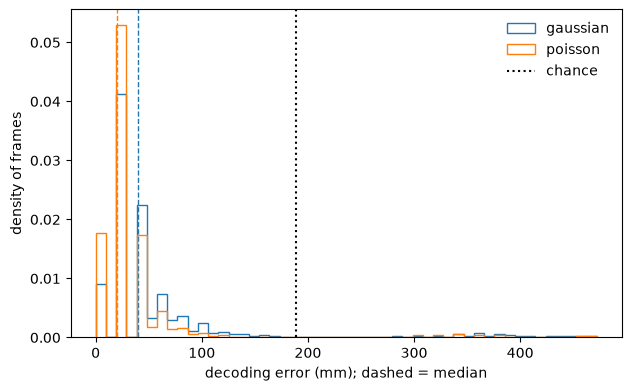

In [95]:
fig, ax = plt.subplots(figsize=(6.2, 3.8), layout="constrained")
bins = np.linspace(0, np.nanpercentile(dec["gaussian"].extras["error"], 99.5), 50)
for i, (k, r) in enumerate(dec.items()):
    ax.hist(r.extras["error"], bins=bins, histtype="step", color=f"C{i}", density=True, label=k)
    ax.axvline(r.extras["error_overall"][0], color=f"C{i}", ls="--", lw=1)
ax.axvline(dec["gaussian"].extras["chance_error"][0], color="k", ls=":", label="chance")
ax.set_xlabel("decoding error (mm); dashed = median"); ax.set_ylabel("density of frames"); ax.legend(frameon=False)
plt.show()

Both decoders beat chance by a wide margin; Poisson does better because it scores a window of activity rather than one frame's value. The `empirical` likelihood is the data-sufficiency problem made concrete: with 400 bins and few positive frames per bin, two levels (silent / active) decode better than five, because the few positive frames get split across four levels, and a **Dirichlet pseudocount** (a small count added to every histogram cell so no likelihood is exactly zero) that is too large pushes the five-level decoder to chance. Both trail Poisson.

The decoder is not specific to space: on categorical states the value per behavior is **recall**. It needs one state per frame, so first make an exclusive version of the social states (overlaps resolved in the listed order, plus a `rest` state). Use `sigma="pooled"` for unbalanced states like these: Shuman's per-state width gives rare behaviors a wide, flat likelihood that wins whenever a cell is active (the numbers and the reason are in `docs/DESIGN.md`).

| `sigma` | meaning | use on |
| --- | --- | --- |
| `per_state` (default) | one width per (cell, state) | grids, where every bin is well sampled |
| `pooled` | one within-state width per cell (as in linear discriminant analysis) | unbalanced categorical states |


In [96]:
session = Pipeline(transforms=[{"name": "bouts_to_states", "source": "social", "output": "social_exclusive",
                                "exclusive": True, "add_rest": True}]).run(session)[0]
spec = lambda sig, shuffle: AnalysisSpec(
    metric={"name": "bayesian_decoder", "sigma": sig, "min_frames_per_class": 20},
    states="social_exclusive", shuffle=shuffle)
bd_soc = Pipeline(analyses=[spec("pooled", dec_shuf)]).run(session)[1]["bayesian_decoder[social_exclusive]"]
bd_ps = Pipeline(analyses=[spec("per_state", None)]).run(session)[1]["bayesian_decoder[social_exclusive]"]
print(f"overall accuracy: pooled {bd_soc.extras['accuracy_overall'][0]:.2f}, "
      f"per_state {bd_ps.extras['accuracy_overall'][0]:.2f}")
pd.DataFrame({"state": bd_soc.state_names, "recall": bd_soc.values,
              "null_hi": bd_soc.shuffle.null_hi, "p": bd_soc.shuffle.p_value}).round(3)

overall accuracy: pooled 0.53, per_state 0.09


,state,recall,null_hi,p
0,sniff,0.515,0.231,0.048
1,chase,0.513,0.211,0.048
2,groom,0.534,0.231,0.048
3,huddle,0.522,0.257,0.048
4,rest,0.549,0.232,0.048


With pooled sigma the decoder should beat its `label_shuffle` null in most or all behaviors, and its overall accuracy should be several times higher than with per-state sigma (on the default seed, roughly 0.4 against about 0.06). With only 20 shuffles the smallest possible p is 1/21 = 0.048, so every behavior that beats its null sits at that floor; raise `n_shuffles` for finer p-values. Recall is modest because only a small fraction of the population is tuned to each behavior and each frame is decoded on its own.


## 13. The choice of null is a one-line change

Everything above used `circular_shift` for single cells and `label_shuffle` for populations. Here is the **same AUROC analysis** on social behavior with three nulls. Only the `null=` entry of `ShuffleConfig` differs:

| null | what is kept | what is broken | typical use |
| --- | --- | --- | --- |
| `circular_shift` | both time series intact | the alignment, by sliding activity | default; single-cell tuning |
| `label_shuffle(block_s)` | activity intact | labels permuted in blocks of `block_s` | population analyses, decoders |
| `bout_shuffle` | activity intact; bout count and durations | bouts re-placed at random times | scored bouts (CaSA's null) |

We report, for each null, the fraction of planted social cells detected **in their own behavior**, and the false-positive rate of untuned cells **per state**. They should be similar here: the simulated data has no confounds that distinguish the nulls. With real data (slow drifts, bursty bouts) the nulls can disagree, and that disagreement is informative.

When the same metric and target appear with different nulls, give each `AnalysisSpec` a `name` (below, `auroc[social]#circular_shift` and so on); the tidy table then has `analysis` and `null` columns that keep them apart.


In [97]:
N_NULL = 100
nulls = {"circular_shift": {"name": "circular_shift", "min_shift_s": 20.0},
         "label_shuffle": {"name": "label_shuffle", "block_s": 2.0},
         "bout_shuffle": {"name": "bout_shuffle"}}
# one named analysis per null; the `null=` entry is the only thing that differs
null_pipe = Pipeline(analyses=[
    AnalysisSpec(name=f"auroc[social]#{label}", metric={"name": "auroc"}, states="social",
                 shuffle=ShuffleConfig(n_shuffles=N_NULL, null=null, seed=0))
    for label, null in nulls.items()])
_, null_res = null_pipe.run(session)
rows = []
for label in nulls:
    r = null_res[f"auroc[social]#{label}"]
    sig = np.asarray(r.shuffle.significant, bool)
    own_ = [r.state_names.index(d["behavior"]) for d in social]
    rows.append({"null": label,
                 "frac_social_detected_own_behavior": sig[ci_soc, own_].mean(),
                 "untuned_FPR_per_state": sig[untuned].mean()})
pd.DataFrame(rows).round(2)


,null,frac_social_detected_own_behavior,untuned_FPR_per_state
0,circular_shift,1.0,0.04
1,label_shuffle,1.0,0.04
2,bout_shuffle,1.0,0.04


### Multiple comparisons: correcting across states

A cell is called "significant in any state" if any of its 4 (social) or 6 (syllable) tests passes, so even untuned cells get several chances. `ShuffleConfig(correction=...)` fills `p_adj` and `significant_adj` next to the raw `p_value` and `significant`. `"max_stat"` compares each state with the largest standardised value across the cell's states in every surrogate, so it controls the family-wise error across states and costs almost nothing; `"bh"` and `"bonferroni"` (with `correction_scope="cells"` to correct across cells) are the alternatives. Here is AUROC on syllables with `max_stat`.

In [98]:
corr_shuf = ShuffleConfig(n_shuffles=200, min_shift_s=20.0, seed=0, correction="max_stat")
corr_pipe = Pipeline(analyses=[AnalysisSpec(metric={"name": "auroc"}, states="syllables", shuffle=corr_shuf)])
_, corr_res = corr_pipe.run(session)
au_c = corr_res["auroc[syllables]"]
sh = au_c.shuffle
print(sh.correction, sh.correction_scope, repr(sh.correction_note))
cell = int(untuned[0])
print(pd.DataFrame({"state": au_c.state_names, "p_value": sh.p_value[cell], "p_adj": sh.p_adj[cell]}).round(3))

max_stat states ''
        state  p_value  p_adj
0       still    0.388  0.905
1        walk    0.259  0.816
2         run    0.806  1.000
3   turn_left    0.100  0.428
4  turn_right    0.438  0.930
5        rear    0.577  0.990


In [99]:
raw_any, adj_any = sh.significant.any(axis=1), sh.significant_adj.any(axis=1)
syl_cells = [d["cell"] for d in gt["syllable_cells"]]
pd.DataFrame(
    {"untuned cells, any state (FPR)": [raw_any[untuned].mean(), adj_any[untuned].mean()],
     "planted syllable cells detected": [raw_any[syl_cells].mean(), adj_any[syl_cells].mean()]},
    index=["raw p_value", "max_stat p_adj"]).round(2)

,"untuned cells, any state (FPR)",planted syllable cells detected
raw p_value,0.19,1.0
max_stat p_adj,0.03,1.0


The false-positive rate on untuned cells drops from the inflated raw value back near alpha while the planted syllable cells are still detected. `cabana.significant_cells` and the classification in the next section use the adjusted values automatically when a correction was run (`adjusted=False` gets the raw ones); see `docs/STATISTICS.md` for the measured numbers and for when to pick `bh` or `bonferroni`.

## 14. Who responds to what: overlap and clusters

These functions work on **results**, not on activity, so they apply to any analysis.

**Overlap vs chance.** Are the place cells (spatial information and split-half stability both significant) and the social-responsive cells (AUROC beyond the null in any state) the same cells more often than independence would predict? `overlap_vs_chance` compares the observed overlap with the **hypergeometric** expectation (the overlap you would get by drawing two cell sets of the same sizes at random), tested with Fisher's exact test. In this simulation the populations are planted as disjoint, so the honest expectation is *less* overlap than chance (odds ratio below 1); with real data an odds ratio above 1 would be the interesting finding (for example, multiplexed coding).

**Classifying cells with criteria.** A cell class such as "place cell" is a rule over analysis results. `place_cell_criteria()` is the usual one (information content *and* split-half stability significant), and `responsive_cell_criteria(results, "social")` makes an excited and an inhibited rule for every state (AUROC above the 97.5th or below the 2.5th percentile of the null). `classify` evaluates them per cell and returns boolean labels that feed `overlap_vs_chance` directly. Rules are `Criteria` objects, so they can be nested (`all_of`, `any_of`, `none_of`) and saved as YAML. The percentile rule uses the raw null, so it is not corrected for the number of states (several untuned cells are called responsive below); `responsive_cell_criteria(..., use_p=True)` instead requires a significant p-value, which is the adjusted one when the analysis was run with a correction.

{'place_cell': 128, 'social_excited': 85, 'social_inhibited': 83}


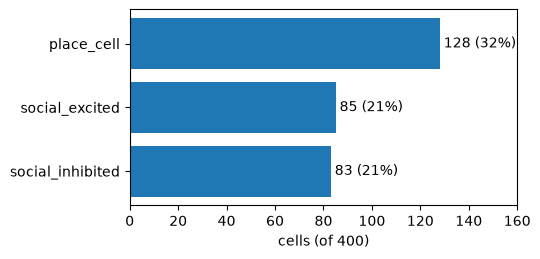

planted           other  place  untuned
classified as                          
multiple              5     40        5
place_cell            2     80        3
social_excited       43      0        8
social_inhibited     50      0       10
unclassified         80      0       74


In [100]:
from cabana import (Criteria, classify, overlap_vs_chance, place_cell_criteria,
                    responsive_cell_criteria, response_features, response_clusters)
ic_pos = results["information_content[position]"]
resp = responsive_cell_criteria(results, "social")      # {"<state>_excited": ..., "<state>_inhibited": ...}
cls = classify(results, {
    "place_cell": place_cell_criteria("position"),
    "social_excited": Criteria(name="social_excited",
                               any_of=[c for k, c in resp.items() if k.endswith("_excited")]),
    "social_inhibited": Criteria(name="social_inhibited",
                                 any_of=[c for k, c in resp.items() if k.endswith("_inhibited")]),
})
print(cls.counts())
fig = cabana.plots.plot_classification(cls)
plt.show()
print(pd.crosstab(pd.Series(cls.label_per_cell(), name="classified as"),
                  pd.Series(np.where(np.isin(np.arange(session.n_cells), place), "place",
                           np.where(np.isin(np.arange(session.n_cells), untuned), "untuned", "other")),
                            name="planted")))

n_a=128 n_b=161 n_both=43 N=400 expected=51.52 odds_ratio=0.6602193419740777 p_value=0.06437431400782065 jaccard=0.17479674796747968 jaccard_chance=0.21694458480714168


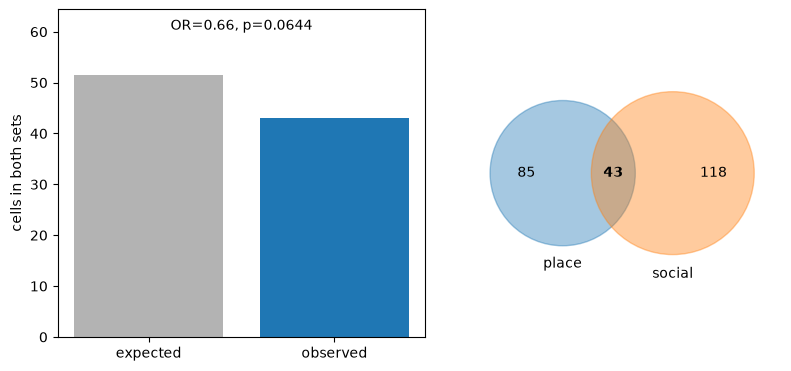

In [101]:
social_any = cls.labels["social_excited"] | cls.labels["social_inhibited"]
ov = overlap_vs_chance(cls.labels["place_cell"], social_any)
print(ov)
fig = cabana.plots.plot_overlap(ov, labels=("place", "social"))
plt.show()

**Response clusters.** Instead of asking about one behavior at a time, describe each cell by its full response profile (here its AUROC and its mean difference in every social behavior), z-score the features and cluster. `k=None` tries k = 2..6 and keeps the best **silhouette** score (how much closer each cell is to its own cluster than to the next nearest one; higher is better). The heatmap shows each cluster's mean profile (row labels give cluster sizes); the right panel is the score for each k. The table compares clusters with the planted populations, which the clustering never saw. Unsupervised clusters rarely match the labels one to one: cells with the same behavior but opposite sign, or weak responders, can group differently.

k = 5, silhouette by k: {2: 0.52, 3: 0.53, 4: 0.56, 5: 0.58, 6: 0.3}


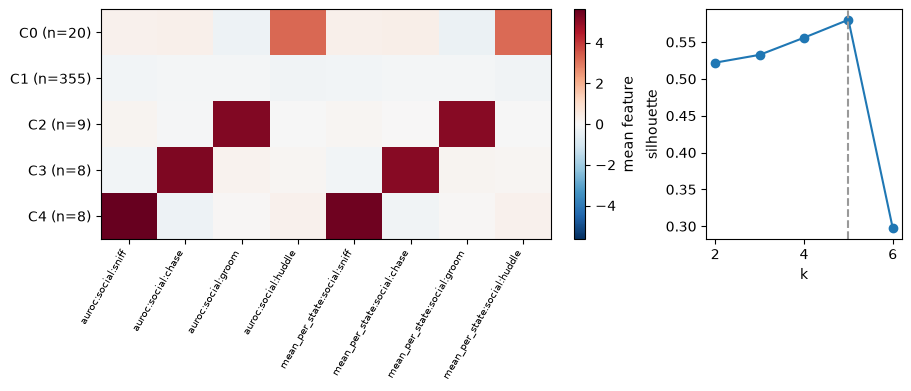

planted population,other,place,social_excited,social_inhibited,syllable,untuned
cluster,,,,,,
0,0,11,9,0,0,0
1,60,109,6,40,40,100
2,0,0,9,0,0,0
3,0,0,8,0,0,0
4,0,0,8,0,0,0


In [102]:
feats, fnames, kept = response_features(
    results, which=[("auroc", "social"), ("mean_per_state", "social")])
clusters = response_clusters(feats, k=None, k_range=(2, 6))
label = np.full(session.n_cells, "other", dtype=object)
label[place] = "place"; label[[d["cell"] for d in gt["syllable_cells"]]] = "syllable"
label[untuned] = "untuned"
for d in social:
    label[d["cell"]] = f"social_{d['sign']}"
print(f"k = {clusters.k}, silhouette by k: { {k: round(v, 2) for k, v in clusters.scores.items()} }")
fig = cabana.plots.plot_clusters(clusters, fnames)
plt.show()
pd.crosstab(pd.Series(clusters.labels, name="cluster"), pd.Series(label[kept], name="planted population"))

## 15. Across sessions and animals

Two small checks of the cohort tools, on short (300 s) simulated sessions so they run quickly. We run the **same pipeline** on two more sessions (seeds 1 and 2) and treat them as: `s0` and `s1` = animal A, `s2` = animal B. Statistics in this field treat the **animal**, not the cell, as the unit of replication, so `fraction_significant_by_animal` pools sessions and cells within animal.

Then a **negative control** for cross-session analysis. `cross_session_map_correlation` correlates each matched cell's rate map in two sessions, against a null that pairs the cell with *other* cells. Normally the `CellMatch` comes from a registration tool (CellReg); here `s0` and `s1` are different simulated animals, so we deliberately register cell *i* to cell *i* (an identity match, which is wrong). Unmatched cells should **not** correlate: median r near 0 and a population p-value that is not small. If this control came out significant, the analysis would be broken.

,analysis,animal,state,n_cells,n_undefined,n_significant,fraction_significant,fraction_positive,fraction_negative
0,auroc[social],A,chase,600,0,46,0.08,0.04,0.03
1,auroc[social],A,groom,600,0,59,0.10,0.04,0.05
2,auroc[social],A,huddle,600,0,77,0.13,0.06,0.07
3,auroc[social],A,sniff,600,0,51,0.08,0.05,0.04
4,auroc[social],B,chase,200,0,18,0.09,0.06,0.04
5,auroc[social],B,groom,200,0,20,0.10,0.08,0.02
6,auroc[social],B,huddle,200,0,33,0.16,0.10,0.06
7,auroc[social],B,sniff,200,0,23,0.12,0.08,0.04


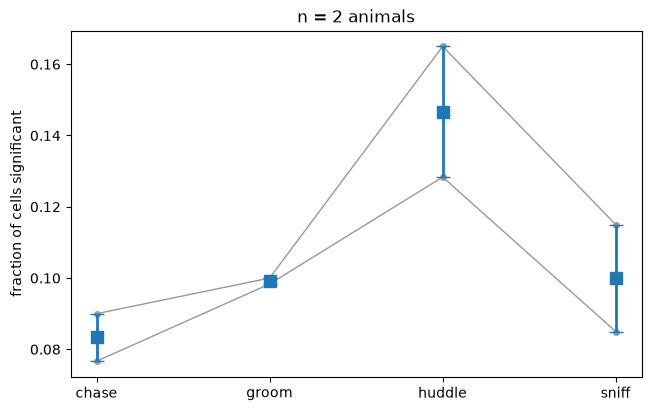

In [103]:
from cabana import (CellMatch, cohort_table, fraction_significant_by_animal,
                    cross_session_map_correlation, remapping_summary)
by_session = {"s0": results}
other = {}
small_pipe = Pipeline(transforms=pipe.transforms, preprocess=pipe.preprocess,
                      analyses=[AnalysisSpec(metric={"name": "information_content", "smooth_sigma_bins": 1.0},
                                             states="position", shuffle=ShuffleConfig(n_shuffles=100, seed=0), masks=["speed"]),
                                AnalysisSpec(metric={"name": "auroc"}, states="social",
                                             shuffle=ShuffleConfig(n_shuffles=100, seed=0))])
for sid, seed in (("s1", 1), ("s2", 2)):
    other[sid], by_session[sid] = small_pipe.run(simulate_session(seed=seed, duration_s=300.0))
animal = {"s0": "A", "s1": "A", "s2": "B"}
table = cohort_table(by_session, animal)
fracs = fraction_significant_by_animal(table, analysis="auroc[social]")
display(fracs.round(2))
fig = cabana.plots.plot_cohort_fractions(fracs)
plt.show()

{'n_pairs': 200, 'n_valid': 200, 'fraction_stable': 0.06, 'median_r': -0.012955902394300976, 'p_population': 0.6965174129353234}


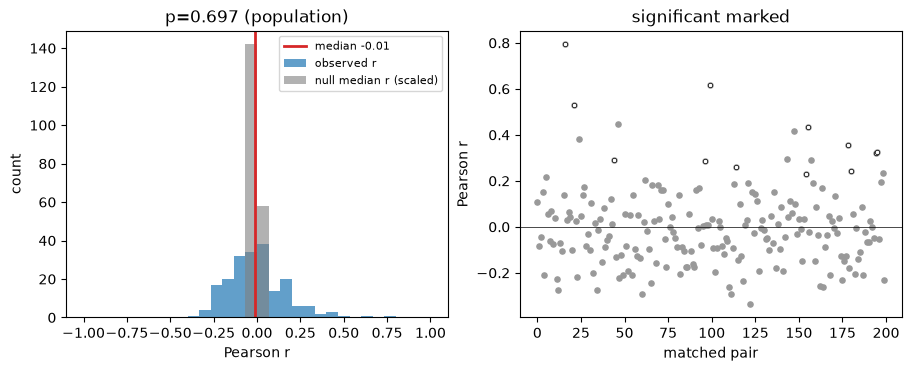

In [104]:
ic_s1 = by_session["s1"]["information_content[position]"]
n_id = min(session.n_cells, other["s1"].n_cells)
ident = CellMatch(session_a="s0", session_b="s1", pairs=np.c_[np.arange(n_id), np.arange(n_id)])
cs = cross_session_map_correlation(ic_pos, ic_s1, ident, n_shuffles=200,
                                   states=(session.states["position"], other["s1"].states["position"]))
print(remapping_summary(cs))
fig = cabana.plots.plot_cross_session(cs)
plt.show()

## 16. Add your own metric

A metric is a pydantic class registered by name. It receives `(activity, states, mask, fs)` and returns an array whose first axis is cells. Every analysis above (including `mean_per_state`, `peth` and `glm_encoding`) is registered exactly this way. Below, the *fraction of frames with any activity* in each state, which the library does not ship. It overrides `check_target` to refuse targets it is not defined for (here, spatial grids). Because it implements only `compute`, the shuffle engine falls back to a plain loop; implementing `compute_shifted` (see `shifted_sums`) makes it fast but is optional.

In [105]:
from typing import ClassVar
import numpy as np
from cabana import Metric, register  # (built-ins are registered the same way)

@register("metric")
class ActiveFraction(Metric):
    """Fraction of masked frames with any activity, in each state."""
    name: ClassVar[str] = "active_fraction"
    default_tail: ClassVar[str] = "two"

    def check_target(self, target):
        super().check_target(target)
        if target.kind == "grid":
            raise ValueError("active_fraction is defined for categorical or bout states")

    def compute(self, activity, states, mask, fs):
        m = states.masked(mask) > 0                        # (n_time, n_states) bool
        out = np.full((activity.shape[0], m.shape[1]), np.nan)
        for s in range(m.shape[1]):
            if m[:, s].any():
                out[:, s] = (activity[:, m[:, s]] > 0).mean(axis=1)
        return out                                         # (n_cells, n_states)

custom = Pipeline(
    transforms=pipe.transforms, preprocess=pipe.preprocess,
    analyses=[AnalysisSpec(metric={"name": "active_fraction"}, states="syllables",
                           shuffle=ShuffleConfig(n_shuffles=100, seed=0))],
)
_, custom_results = custom.run(session)
r = custom_results["active_fraction[syllables]"]
print("significant (cell, syllable) pairs:", int(r.shuffle.significant.sum()))
custom_results.to_dataframe().query("significant").head()

ValueError: metric plugin 'active_fraction' is already registered

## 17. Save the run

Everything is saved with one call each. `results.save` writes a directory or `.zip` (a JSON manifest plus compressed arrays, including the null distributions) that `cabana.ResultSet.load` reads back; `results.to_dataframe()` gives the flat table for pandas or R; and the pipeline YAML fully describes the analysis, so it can be re-run on another session.

**What to look for in the YAML:** a `transforms:` list (how behavior became states), `preprocess:` (masks), and one entry per analysis with its metric parameters, target, shuffle settings and masks. If a colleague has this file and your raw data, they can reproduce every number.


In [ ]:
from pathlib import Path

out = Path("output")          # notebooks/output/ is git-ignored
out.mkdir(exist_ok=True)
results.save(out / "results.zip")
df = results.to_dataframe()
df.to_csv(out / "results.csv", index=False)
pipe.to_yaml(out / "pipeline.yaml")
print(df.shape, "rows in the tidy table; columns:", list(df.columns))
print(len(cabana.ResultSet.load(out / "results.zip")), "results reloaded")
print((out / "pipeline.yaml").read_text()[:600])


### Watching a run: progress and cancellation

`Pipeline.run(session, context=RunContext(...))` takes callbacks. `on_progress` receives a `ProgressEvent` (stage, name, overall `fraction`, shuffles done) at every stage, analysis end and shuffle batch; `should_cancel` is polled between analyses and after every shuffle batch and makes `run` return the partial results with `status="cancelled"` instead of raising; `on_error="record"` keeps going past a failing analysis. These are what a front end such as CaLab needs; `cabana.describe()` lists the registered metrics and their parameter schemas as JSON.

In [ ]:
from cabana import RunContext

tiny = Pipeline(analyses=[
    AnalysisSpec(metric={"name": "auroc"}, states="social", shuffle=ShuffleConfig(n_shuffles=100, seed=0)),
    AnalysisSpec(metric={"name": "information_content"}, states="syllables", shuffle=ShuffleConfig(n_shuffles=100, seed=0)),
])
seen, finished = [], []
def on_progress(ev):
    seen.append(ev)
    if ev.stage == "analysis" and ev.message == "finished":
        finished.append(ev.name)
        print(f"{ev.fraction:4.0%}  finished {ev.name}  ({ev.elapsed_s:.1f} s)")

_, ok = tiny.run(session, context=RunContext(on_progress=on_progress))
print(ok.status, ok.completed, f"{len(seen)} progress events")
# cancel as soon as the first analysis is done: the partial results come back
finished.clear()
_, part = tiny.run(session, context=RunContext(on_progress=on_progress, should_cancel=lambda: bool(finished)))
print(part.status, part.completed)
caps = cabana.describe()
print(caps["version"], len(caps["plugins"]["metric"]), "registered metrics")

## 18. Evidence-first views

Everything above picked a figure by hand. Each result also knows which figures are informative for its metric (`Metric.default_plots`), so one call draws them, and a **cell card** puts all the evidence for one cell on one page. [`docs/PLOTS.md`](../docs/PLOTS.md) says what each figure shows and what to look for.

**What to look for:** a card whose bold titles (significant after any correction) sit above pictures that show the structure the number claims: a compact field, a bar outside the grey null range. A small p with an unremarkable picture deserves suspicion. "(floor)" in a p means no surrogate reached the observed value, so the p is limited by the number of shuffles.

In [ ]:
fig = results["information_content[position]"].plot(session)   # the metric's first default figure
print(results["information_content[position]"].plots(session))  # everything that applies
plt.show()

In [ ]:
import tempfile
figs = results.plot_all(session, out_dir=tempfile.mkdtemp(prefix="cabana_all_"))  # every default figure to disk
print(len(figs), "figures:")
for key in list(figs)[:8]:
    print(" ", key)

In [ ]:
cards = cabana.plots.plot_cell_cards(session, results, cells="significant", max_cards=1)
card = next(iter(cards.values()))
plt.show()

**Session QA and agreement.** `plot_session_qa` shows whether each state has enough data, bouts and unmasked frames to support an estimate. `plot_analysis_agreement` shows how much the analyses agree on which cells are significant; cells that only one analysis calls are weaker evidence.

In [ ]:
fig = cabana.plots.plot_session_qa(session)
plt.show()
fig = cabana.plots.plot_analysis_agreement(results, kind="jaccard")
plt.show()

## 19. Nulls that answer a confound

A circular shift answers "is this cell more tied to the behavior than a shifted copy of itself". It cannot tell a behavior from a covariate that rides on it. If a cell fires with speed and the animal moves faster in some social states, the cell looks state-selective for a reason that has nothing to do with the state.

`covariate_matched_shift` keeps only the shifts under which every state sees the same distribution of speed as it does in the data. Two numbers in `null_info` say how well that worked: `acceptance_rate` (the share of candidate shifts that passed) and `balance_max` (the worst mismatch among accepted shifts; it never exceeds `tolerance`). `tolerance` has to scale with state size, because a small state has a noisy speed distribution even under a perfect null. Details: `docs/STATISTICS.md`, "Choosing a null".

In [ ]:
matched = {"name": "covariate_matched_shift", "covariate": "speed", "statistic": "mean",
           "tolerance": 0.5, "min_frames": 100, "max_tries": 100, "min_shift_s": 10.0}
phase_e = Pipeline(analyses=[
    AnalysisSpec(name="auroc_plain", metric={"name": "auroc"}, states="social",
                 shuffle=ShuffleConfig(n_shuffles=N_SHUFFLES, min_shift_s=10.0, seed=15)),
    AnalysisSpec(name="auroc_speed_matched", metric={"name": "auroc"}, states="social",
                 shuffle=ShuffleConfig(n_shuffles=N_SHUFFLES, null=matched, seed=16)),
])
_, pe_res = phase_e.run(session)
plain, speed_matched = pe_res["auroc_plain"], pe_res["auroc_speed_matched"]
info = speed_matched.shuffle.null_info
untuned_idx = np.array(gt["untuned_cells"])
print(f"acceptance rate {info['acceptance_rate']:.0%} of {info['n_candidates']} candidate shifts; "
      f"balance_max {info['balance_max']:.2f} (tolerance {info['tolerance']}), "
      f"balance_mean {info['balance_mean']:.2f}")
for name, r in (("circular shift", plain), ("speed-matched", speed_matched)):
    sig = cabana.significant_cells(r)
    print(f"{name:15s} cells significant in any social state: {int(sig.sum())}; "
          f"untuned cells called significant: {int(sig[untuned_idx].sum())} of {len(untuned_idx)}")

States that are *defined by* the covariate cannot be speed-matched. The simulator's syllables are defined by speed, so no shift keeps every syllable's speed distribution; the null raises instead of returning a weak answer. That is the right outcome: the question has no answer under that confound.

In [ ]:
try:
    Pipeline(analyses=[AnalysisSpec(metric={"name": "auroc"}, states="syllables",
        shuffle=ShuffleConfig(n_shuffles=20, null={"name": "covariate_matched_shift",
                              "covariate": "speed", "tolerance": 0.1, "max_tries": 20}))]).run(session)
except ValueError as e:
    print("raises:", str(e)[:200])

### Population metrics need `cell_shift`

A common shift moves every cell together, so it leaves cell-to-cell correlations and the participation ratio exactly as observed. `cell_shift` rolls each cell by its own offset (`min_pair_separation_s` keeps any two offsets apart), which removes coordination and keeps each cell's own statistics. Noise correlations are the correlations left after subtracting each syllable's mean activity; the participation ratio is the effective number of dimensions of the population.

In [ ]:
cs = {"name": "cell_shift", "min_pair_separation_s": 2.0}
pop_pipe2 = Pipeline(analyses=[
    AnalysisSpec(name="noise_corr", metric={"name": "pairwise_correlation", "kind": "noise"},
                 states="syllables", shuffle=ShuffleConfig(n_shuffles=50, null=cs, seed=17)),
    AnalysisSpec(name="pr", metric={"name": "participation_ratio"}, states="syllables",
                 shuffle=ShuffleConfig(n_shuffles=50, null=cs, seed=18)),
])
_, pr_res = pop_pipe2.run(session)
nc, pr = pr_res["noise_corr"], pr_res["pr"]
print(f"noise correlations: mean off-diagonal {float(np.ravel(nc.extras['mean_offdiag'])[0]):+.4f}")
print(f"participation ratio {pr.values[0]:.1f} of {session.n_cells} cells "
      f"(null {pr.shuffle.null_lo[0]:.1f} to {pr.shuffle.null_hi[0]:.1f}, p={pr.shuffle.p_value[0]:.3f})")
fig = cabana.plots.plot_pairwise_matrix(nc, vmin=-0.2, vmax=0.2)   # weak coupling: narrow colour range
plt.show()

### Effect sizes: the `z` column

A p-value cannot go below `1 / (n_shuffles + 1)`, so many cells tie at the floor. `z = (observed - null mean) / null sd` is an effect size on one scale that does not hit the floor (it is NaN where the null is constant). It is descriptive: null distributions of bounded statistics are not Gaussian.

In [ ]:
df = pe_res.to_dataframe()
df = df[df["analysis"] == "auroc_speed_matched"].copy()
df["abs_z"] = df["z"].abs()
print(f"p floor with {N_SHUFFLES} shuffles (two-sided): {2 / (N_SHUFFLES + 1):.4f}")
df.sort_values("abs_z", ascending=False)[["cell", "state", "value", "p_value", "z"]].head(8).round(4)

### Place fields

`place_fields` thresholds each rate map (half the peak by default), labels connected components and reports field count, area, centroid and the ratio of mean rate inside fields to outside. `plot_place_fields` outlines the field; look for one compact outline around the bright patch with the centroid inside it.

In [ ]:
fields_pipe = Pipeline(analyses=[AnalysisSpec(
    name="fields", metric={"name": "place_fields", "min_field_bins": 2}, states="position",
    masks=["speed"], shuffle=ShuffleConfig(n_shuffles=100, min_shift_s=20.0, seed=11))])
fields = fields_pipe.run(session)[1]["fields"]
place_ids = np.array(gt["place_cells"])
show = place_ids[np.argsort(-np.nan_to_num(fields.values[place_ids]))[:6]]
fig = cabana.plots.plot_place_fields(session, fields, list(show), ncols=3)
plt.show()

## 20. The front door: `analyze`, `summary`, `validate` and the command line

Sections 2 to 19 built pipelines by hand so every choice was visible. Day to day you usually want
the other direction: name the question, point at a state space, get a table. CaBaNA ships
**recipes** for the common questions, and `cabana.analyze` runs one in a single call: it fills the
placeholders, checks the pipeline against your session, runs it and returns the processed session
and a `ResultSet`. The same pipeline can then be run from a terminal with `cabana run`, which is how
a cluster job, a script in another language or the future CaLab app will drive it.

These cells reuse `session` from above (position, social and syllable states and a `speed` mask are
already in it).

In [ ]:
import warnings
from pathlib import Path

print(cabana.recipes())
fd_pipe = cabana.recipe_pipeline("place_cell", states="position")
print("\n".join(fd_pipe.to_yaml().splitlines()[:40]))

A recipe is **just a pipeline with placeholders**: `recipe_pipeline` returns an ordinary `Pipeline`
(here with `states="position"` filled in) that you can print, edit, save or run like any other.
`cabana.recipe(name)` shows the raw recipe, its `targets` (what you must supply) and `defaults`.
See [`docs/RECIPES.md`](../docs/RECIPES.md).

### Check before you run: `validate`

`pipeline.validate(session)` is a preflight check that runs no analysis. It reports **errors** (a
state space or signal that is not in the session, a mask that does not exist, a null that does not
suit the metric or a shift longer than the session, a shuffle count too small to ever reach alpha) and **warnings** (empty
states, very small states), and an **estimate of time and peak memory** from a short timing run. `analyze` runs the same check and raises with this report if it finds errors. Below, the
good pipeline, then a deliberately bad one: 19 shuffles can give a smallest p-value of 0.05, which
can never be below alpha = 0.05. We print the report instead of raising.

In [ ]:
print(fd_pipe.validate(session))
print()
bad = cabana.recipe_pipeline("place_cell", states="position", n_shuffles=19)
print(bad.validate(session))

### One call: `analyze` and `results.summary()`

`summary()` is one row per analysis: what was tested, how many cells, how many are significant (raw
and adjusted), the median effect size `z`, and any warnings or error. Pass `out_dir=` to also write
`results.zip`, `pipeline.yaml` and `summary.csv`. `analyze` also re-emits validation warnings as
Python warnings; we silence them here because the report above already showed them.

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fd_session, fd_res = cabana.analyze(
        session, "place_cell", states="position", n_shuffles=200, progress=False
    )
fd_res.summary()[["analysis", "metric", "n_shuffles", "n_tested", "n_significant",
                  "frac_significant", "median_z"]]

### Overriding a parameter

Any parameter can be overridden with its path, as in `Pipeline.set_param` (`*` matches every
analysis). A value you give **beats the automatic selector**: the recipe's `auto_smooth_sigma` would
otherwise choose the smoothing by held-out score, but a typed value is final. It is recorded in
`results.selections` as a `user_pick`, so the provenance says who chose it.

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    _, fd_res_s1 = cabana.analyze(
        session, "place_cell", states="position", n_shuffles=100, progress=False,
        **{"analyses.*.metric.smooth_sigma_bins": 1.0},
    )
pd.DataFrame(fd_res_s1.selections)[["path", "value", "method", "informed_by_significance"]]

### Memory, and the chunked null

`cabana.memory_estimate(pipeline, session)` says how big each analysis' null distribution is and
what the peak will be, without running anything. Big sessions (many cells, many states, thousands
of shuffles) can exceed `ShuffleConfig.max_null_bytes`; with `keep_null="none"` the engine then
evaluates the null **in chunks of cells** and discards each chunk's null after taking its p-values
and bounds. The p-values are the same as the unchunked run. Here we force it by setting
`max_null_bytes=1`, so every cell is its own chunk.

In [ ]:
print(cabana.memory_estimate(fd_pipe, fd_session))

def auroc_social(**kw):
    spec = AnalysisSpec(name="a", metric={"name": "auroc"}, states="social",
                        shuffle=ShuffleConfig(n_shuffles=100, **kw))
    return Pipeline(analyses=[spec]).run(fd_session)[1]["a"]

full = auroc_social()
chunked = auroc_social(keep_null="none", max_null_bytes=1)
print("chunks:", chunked.shuffle.null_info["chunks"],
      "| identical p:", np.allclose(full.shuffle.p_value, chunked.shuffle.p_value),
      "| max abs difference:", np.abs(full.shuffle.p_value - chunked.shuffle.p_value).max())

### Tuning a parameter and exporting the choice

`cabana.tune` sweeps a parameter, picks a value with a rule and returns a **`TuningExport`**: the
chosen values plus the evidence (candidates, criterion, rule, hashes of the session and pipeline).
`pipeline.apply_tuning(export)` writes the values into a pipeline and records each as a selection.
Choose by a **reliability criterion**, never by significance (the guard rail from section 5 refuses
`frac_significant`). `median_value` is a reliability here only because the metric is
`split_half_stability`; do not use it on `information_content`, whose bias grows with smoothing.

In [ ]:
split_only = Pipeline(analyses=[AnalysisSpec(
    name="split", metric={"name": "split_half_stability"}, states="position", masks=["speed"])])
export = cabana.tune(fd_session, split_only,
                     {"analyses.*.metric.smooth_sigma_bins": [0, 1, 2]}, criterion="median_value")
tuned = split_only.apply_tuning(export)
print("chosen:", export.chosen, "->", tuned.analyses[0].metric.smooth_sigma_bins)
print(export.to_json()[:600])

### The same run from a terminal

A pipeline YAML and a saved session are all `cabana run` needs. Progress goes to stderr as text, or
as one JSON object per line (`--progress jsonl`) that another program can read live:

```bash
cabana run pipeline.yaml --session session.zip --out out/ --progress jsonl
cabana describe            # what this install can do: metrics, nulls, transforms, as JSON
cabana schema resultset    # the JSON Schema of a saved ResultSet
cabana validate pipeline.yaml --session session.zip
```

Exit codes: 0 ok, 1 error, 2 usage, 3 cancelled, 4 finished with failed analyses. Full reference in
[`docs/CLI.md`](../docs/CLI.md). The cell below does the same in-process by calling the CLI's entry
point, writing to `output/front_door/`.

In [ ]:
from cabana._cli import main as cabana_main

fd_dir = Path("output/front_door")
(fd_dir / "cli").mkdir(parents=True, exist_ok=True)   # the progress file's folder must exist
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cabana.analyze(session, "place_cell", states="position", n_shuffles=100,
                   progress=False, out_dir=fd_dir)
fd_session.save(fd_dir / "session.zip")
rc = cabana_main(["run", str(fd_dir / "pipeline.yaml"), "--session", str(fd_dir / "session.zip"),
                  "--out", str(fd_dir / "cli"), "--progress", "jsonl",
                  "--progress-file", str(fd_dir / "cli" / "progress.jsonl")])
lines = (fd_dir / "cli" / "progress.jsonl").read_text().splitlines()
print("exit code", rc, "|", len(lines), "jsonl lines | last:", lines[-1])

### What CaLab will consume

The front door is also the contract for tools that are not Python: `cabana.describe()` (what exists
and each parameter's type, default and range, so an app can build its forms), the JSON Schemas in
`schemas/` such as `resultset-v1.json` (what a saved result looks like), the jsonl progress stream
(live status and cancellation), and `TuningExport` (the document a slider app posts back to
`apply_tuning`).

### Head direction and pitch cells

The simulated session also carries a head-orientation quaternion (`head_w` to `head_z`, like a Miniscope V4 BNO sensor), a population of head-direction cells (von Mises tuning to yaw) and a few pitch cells (activity rises or falls with nose-up pitch). The `head_orientation` recipe needs only the raw quaternion: `analyze` adds `resample_signal` and the `head_orientation` transform, which write `head_yaw`, `head_pitch` and `head_roll` in degrees (head frame x forward, y left, z up; yaw 0 = +x, counter-clockwise from above; pitch is nose-up positive; positive roll is right ear down). A real sensor's yaw zero is its power-on heading, so on your own data set `yaw_offset_deg` on the `head_orientation` transform and check the signs against a known movement such as rearing.

Yaw is tested with circular tuning (mean vector length and preferred direction). Pitch coding is often monotonic, so correlation is the primary test and binned tuning information, which needs a bump, is the second.

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ho_session, ho_res = cabana.analyze(
        session, "head_orientation", n_shuffles=N_SHUFFLES, progress=False
    )
ho_res.summary()[["analysis", "metric", "n_shuffles", "n_tested", "n_significant", "median_z"]]

In [ ]:
def hits(name, cells):
    sig = np.asarray(ho_res[name].shuffle.p_value).reshape(-1) < 0.01
    return int(sig[cells].sum()), sig

hd_cells = [d["cell"] for d in gt["head_direction_cells"]]
pitch_cells = [d["cell"] for d in gt["pitch_cells"]]
untuned_all = gt["untuned_cells"]
n_hd, sig_hd = hits("head_direction", hd_cells)
n_pc, sig_pc = hits("pitch_correlation", pitch_cells)
n_pt, _ = hits("pitch_tuning", pitch_cells)
print(f"head direction: {n_hd} of {len(hd_cells)} planted cells (untuned false positives "
      f"{int(sig_hd[untuned_all].sum())} of {len(untuned_all)})")
print(f"pitch: correlation finds {n_pc} of {len(pitch_cells)}, binned tuning {n_pt} "
      f"(untuned false positives with correlation {int(sig_pc[untuned_all].sum())})")

# preferred direction against the planted one (sensor yaw = arena yaw - head_yaw_offset_deg)
off = gt.get("head_yaw_offset_deg", 0.0)
pref = ho_res["head_direction"].extras["preferred_direction"]
err = [abs((pref[d["cell"]] - (d["preferred_deg"] - off) + 180) % 360 - 180)
       for d in gt["head_direction_cells"] if sig_hd[d["cell"]]]
print(f"preferred-direction error of the detected cells: median {np.median(err):.1f} deg, "
      f"max {np.max(err):.1f} deg")

fig = cabana.plots.plot_circular_tuning(ho_res["head_direction"], hd_cells[:8])
plt.show()
fig = cabana.plots.plot_ground_truth_recovery(ho_session, ho_res)
plt.show()

## 21. Your own data

If your files come from Minian, CaImAn, DeepLabCut, BORIS, Keypoint-MoSeq or CaMAP, `cabana.loaders` reads them (see below). Otherwise you build a `Session` from arrays you already have. `t` is in seconds on the neural clock (any origin), and behavior inputs (position, bouts, labels) use the same time base. They may start before imaging; `resample_signal` interpolates them onto `t`.

The full guide, with BORIS bouts, DeepLabCut position, exclusive states, masks, classifying cells, several sessions and a custom metric, is [`docs/BRING_YOUR_OWN_DATA.md`](../docs/BRING_YOUR_OWN_DATA.md).

Before trusting a smoothing width or bin size on your own data, repeat section 5 on it: let `auto_smooth_sigma` choose, look at a sweep, and report the `Selection` records.


In [ ]:
from cabana import BoutTable, ContinuousSignal, Session

t_xy = np.arange(-1.0, 1201.0, 1 / 30)   # DLC timestamps, starting 1 s before imaging
xy = np.random.default_rng(0).uniform(0, 400, (t_xy.size, 2))
mine = Session(
    activity=session.activity, t=session.t, fs=session.fs,   # (n_cells, n_time) array, seconds, Hz
    activity_kind="deconvolved", cell_ids=[f"c{i:03d}" for i in range(session.n_cells)],
    behavior={
        "social": BoutTable(labels=["sniff", "groom"], start_s=[70.0, 120.0], stop_s=[74.0, 130.0],
                            scored_start_s=30.0, scored_stop_s=1170.0),
        "position": ContinuousSignal(t=t_xy, values=xy, channel_names=["x", "y"], units="mm"),
    },
)
print(mine.n_cells, "cells,", mine.n_time, "frames;", sorted(mine.behavior))


### Loading your own files

`cabana.loaders` reads the common formats (install the extras with `pip install "cabana[loaders]"`, or `cabana[minian]` / `cabana[caiman]` for one). Behavior files count time from the first video frame, so pass `t_offset_s`, the moment imaging started in video time: `t_neural = t_video - t_offset_s`. This example is not executed here; `docs/LOADERS.md` has the formats, the optional dependencies and the caveats (pass `scored_span` to `load_boris`; the `.camap` loader was only tested on synthetic bundles).

```python
from cabana import loaders

OFFSET = 12.4  # imaging started 12.4 s into the video
session = loaders.load_caiman("caiman.hdf5", activity="S", fs=15.0)   # or load_minian / load_camap
xy = loaders.dlc_centroid(
    loaders.load_dlc("dlc.csv", fs_video=30.0, t_offset_s=OFFSET, px_per_mm=2.5), ["nose", "tail"])
bouts = loaders.load_boris("boris.csv", t_offset_s=OFFSET, scored_span=(40 - OFFSET, 600 - OFFSET))
syllables = loaders.load_moseq("moseq.csv", fs_video=30.0, t_offset_s=OFFSET)
session.behavior.update(position=xy, social=bouts, syllables=syllables)
```

## What's next

- **Your own data:** see the next section and [`docs/BRING_YOUR_OWN_DATA.md`](../docs/BRING_YOUR_OWN_DATA.md).
- **Real data:** `cabana.loaders` (Minian, CaImAn, DeepLabCut, BORIS, Keypoint-MoSeq, `.camap`) fills the same three arrays; see [`docs/LOADERS.md`](../docs/LOADERS.md).
- **Registration:** `CellMatch` is a container; wiring CellReg output into it is the loader's job.
- **More analyses from the survey:** see `docs/ANALYSIS_COVERAGE.md` for what is implemented and what is not.
- **CaLab app:** CaBaNA is intended to become an app within [CaLab](https://github.com/miniscope/CaLab).

The point of the demo: the loader and the transform are where experiments differ. Everything in the middle (metrics, masks, nulls, plots) is shared.